<a href="https://colab.research.google.com/github/Murasakiowo/Machine-Learning/blob/main/FML_R2_S3_G9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


#RETO 2 - MACHINE LEARNING
###Santiago Cárdenas & Daniel Mayorga Lang
---



**1. EXPLICACIÓN GENERAL DEL PROBLEMA**

En el contexto de la hadronterapia, una técnica de radioterapia que utiliza partículas pesadas
cargadas (protones e iones de carbono) para tratar tumores, se ha desarrollado un nuevo proceso
de bajo costo para generar haces de protones. Sin embargo, este proceso produce también rayos
gamma residuales de alta energía, los cuales no son deseados para el tratamiento, pues podrían
comprometer la precisión y seguridad del procedimiento al irradiar tejido sano.

Para garantizar que únicamente los haces adecuados lleguen al paciente, se requiere una etapa de
clasificación automática antes del transporte al gantry. Un detector registra seis
características físicas de cada haz generado, y a partir de ellas se busca determinar si el haz
corresponde a un hadrón (clase 1) o a un rayo gamma (clase 0).

Este es un problema de clasificación binaria supervisada: se dispone de un conjunto de datos
etiquetado con 10.700 observaciones de entrenamiento y 2.676 observaciones de prueba, donde cada
observación representa un haz detectado y está descrita por seis variables continuas: `fLength`,
`fWidth`, `fConc1`, `fM3Long`, `fAlpha` y `fDist`. El objetivo es entrenar una red neuronal
artificial (ANN) que aprenda a distinguir entre ambas clases con la mayor precisión posible,
priorizando especialmente el recall sobre los hadrones, dado que clasificar erróneamente un
hadrón como rayo gamma implicaría descartar un haz terapéutico válido, reduciendo la eficacia
del tratamiento.

**2. DEFINICIÓN DE TODOS LOS COMPONENTES**



---



### 2.1 Objetivo
La variable que queremos predecir es `class`, donde el valor $y = 1$ representa un hadrón y el valor $y = 0$ representa un rayo gamma.

A partir de las estadísticas descriptivas iniciales, se observa que la media de la variable `class` es cercana a $0.5$, Esto sugiere que las clases están relativamente balanceadas.

---

### 2.2 Variables explicativas:
 La base de entrenamiento tiene $10.700$ observaciones y seis variables explicativas: `fLength`,
`fWidth`, `fConc1`, `fM3Long`, `fAlpha` y `fDist`. Estas variables son las características medidas por el detector para cada haz.Sea $ \mathbf{x} \in \mathbb{R}^6$ el vector de
características de una observación:

$$\mathbf{x} = (\text{fLength},\ \text{fWidth},\ \text{fConc1},\ \text{fM3Long},\ \text{fAlpha},\ \text{fDist})$$

- **fLength**: media $\approx 57.77$, mediana $= 39.16$. La diferencia entre ambas sugiere
  asimetría positiva con valores atípicos altos (máximo $= 334.18$).
- **fWidth**: media $\approx 23.84$, mediana $= 17.37$. Distribución similar a `fLength`,
  con cola derecha.
- **fConc1**: escala mucho menor, entre $0.0003$ y $0.6752$. Media $= 0.2134$, mediana
  $= 0.1961$, relativamente simétrica.
- **fM3Long**: toma valores negativos y positivos, entre $-318.30$ y $231.45$. Desviación
  estándar $\approx 56.92$, alta variabilidad.
- **fAlpha**: valores en $[0°,\ 90°]$, media $= 31.24$, mediana $= 22.68$, con concentración
  en valores bajos.
- **fDist**: media $= 196.05$ y mediana $= 194.43$, distribución centrada. Desviación estándar
  $\approx 76.71$.

Dado que las variables presentan diferencias deescala considerables, se aplicó estandarización
mediante el StandardScaler, que transforma cada variable según:

$$x'_j = \frac{x_j - \mu_j}{\sigma_j}$$

donde $\mu_j$ y $\sigma_j$ son la media y desviación estándar de la variable $j$ estimadas
sobre el conjunto de entrenamiento.

---
### 2.3 Arquitetctura de la red neuronal
Se implementó una red neuronal artificial (ANN) de tipo feedforward con la siguiente
estructura general. Para una capa oculta con función de activación ReLU, la transformación
en la capa $l$ es:

$$\mathbf{h}^{(l)} = \text{ReLU}\!\left(\mathbf{W}^{(l)}\mathbf{h}^{(l-1)} + \mathbf{b}^{(l)}\right)$$

donde $\text{ReLU}(z) = \max(0, z)$, $\mathbf{W}^{(l)}$ es la matriz de pesos y $\mathbf{b}^{(l)}$
el vector de sesgos de la capa $l$.

La **capa de salida** produce una probabilidad mediante la función sigmoide:

$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

donde $\hat{y} \in (0, 1)$ se interpreta como la probabilidad de que el haz sea un hadrón.
La clase predicha se obtiene aplicando un umbral:

$$\hat{y}_{\text{clase}} = \begin{cases} 1 & \text{si } \hat{y} \geq 0.5 \\ 0 & \text{si } \hat{y} < 0.5 \end{cases}$$

---
### 2.4 Función de pérdida
Para clasificación binaria se utiliza la entropía cruzada binaria (binary cross-entropy):

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i)\right]$$

donde $N$ es el número de observaciones, $y_i \in \{0, 1\}$ es la etiqueta real y $\hat{y}_i$
es la probabilidad predicha por el modelo para la observación $i$.

---
### 2.5 Optmiziador

Se utilizó el optimizador Adam (*Adaptive Moment Estimation*), que adapta la tasa de
aprendizaje para cada parámetro combinando momentum de primer y segundo orden:

$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon}\hat{m}_t$$

donde $\hat{m}_t$ y $\hat{v}_t$ son las estimaciones corregidas del primer y segundo momento
del gradiente, respectivamente, y $\eta$ es la tasa de aprendizaje.

---
### 2.6 Proceso de entrenamiento y partición de datos

El conjunto de entrenamiento (`hadron_train.csv`, $n = 10.700$) se dividió en:

- Entrenamiento: $75\%$ ($8.025$ observaciones)
- Validación: $25\%$ ($2.675$ observaciones)

Esta proporción se justifica porque el conjunto de prueba representa aproximadamente el $20\%$
del total de datos ($2.676$ observaciones), por lo que extraer un $25\%$ del archivo de train
equivale a mantener una validación de tamaño comparable. Se utilizó `stratify=Y` para preservar
la proporción de clases en cada partición.

---
### 2.7 Regularización

Se aplicaron dos técnicas de regularización para controlar el sobreajuste:

- Dropout: en cada paso de entrenamiento, cada neurona se desactiva con probabilidad $p$,
  lo que equivale a entrenar un conjunto de sub-redes y reduce la co-adaptación entre neuronas.
- Early Stopping: se monitorea el recall en validación y se detiene el entrenamiento si
  no mejora durante un número de épocas consecutivas (`patience`), restaurando los pesos del
  mejor modelo.

---
### 2.8 Métricas de evaluación

Las métricas utilizadas para evaluar los modelos son:

- Accuracy:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

- Recall (sensibilidad), métrica principal de este reto:

$$\text{Recall} = \frac{TP}{TP + FN}$$

donde $TP$ son los verdaderos positivos (hadrones clasificados correctamente), $FN$ los
falsos negativos (hadrones clasificados como gamma), $TN$ los verdaderos negativos y $FP$
los falsos positivos.

- Matriz de confusión: resume visualmente los cuatro tipos de clasificación posibles
  (TP, TN, FP, FN).


**APÉNDICE APARTADO 2**




**A2.1 SOBRE LAS VARIABLES EXPLICATIVAS**

In [ ]:
import pandas as pd



df_hadron=pd.read_csv("/content/sample_data/hadron_train.csv")

df_hadron = df_hadron.drop(columns="Unnamed: 0")

print(df_hadron.describe())
df_hadron

            fLength        fWidth        fConc1       fM3Long        fAlpha  \
count  10700.000000  10700.000000  10700.000000  10700.000000  10700.000000   
mean      57.772289     23.844115      0.213421      7.130030     31.239051   
std       47.139296     20.915903      0.112549     56.919276     27.048159   
min        4.283500      0.000000      0.000300   -318.300200      0.000000   
25%       24.891275     11.757575      0.125400    -14.931900      7.087150   
50%       39.161650     17.367250      0.196100     14.606650     22.677000   
75%       77.122350     26.481000      0.284825     35.089925     52.233325   
max      334.177000    228.038500      0.675200    231.446000     90.000000   

              fDist         class  
count  10700.000000  10700.000000  
mean     196.049416      0.498692  
std       76.712825      0.500022  
min        1.282600      0.000000  
25%      142.962425      0.000000  
50%      194.434500      0.000000  
75%      243.584525      1.000000  


,fLength,fWidth,fConc1,fM3Long,fAlpha,fDist,class
0,158.3120,46.8503,0.1555,141.5280,2.9828,106.1760,1
1,24.8738,19.3399,0.1648,-13.6964,31.2269,68.9708,0
2,43.6872,20.4355,0.2482,34.2563,71.4563,158.8940,1
3,19.1636,9.9135,0.4277,-14.4368,24.6194,228.0200,0
4,34.6563,21.1375,0.1528,29.9303,24.7650,55.6633,0
...,...,...,...,...,...,...,...
10695,47.8877,29.0881,0.1903,7.6255,22.0716,87.0570,1
10696,25.5481,17.8718,0.2228,-21.5742,13.7980,149.0380,1
10697,47.3271,23.1339,0.1266,-8.1362,2.9820,210.2490,0
10698,169.0402,35.3614,0.1986,70.4636,48.5542,326.2363,1


**3. IMPLEMENTACIÓN DEL CÓDIGO**


1. Se preparan los datos, con el vector de la clase y la matriz de las variables explicativas

In [ ]:
#Vector de la clasificación real
# 1 - hadrón
# 0 - rayo gamma


Y = df_hadron["class"]

X = df_hadron.drop(columns="class")


print(Y)
print(X)


0        1
1        0
2        1
3        0
4        0
        ..
10695    1
10696    1
10697    0
10698    1
10699    0
Name: class, Length: 10700, dtype: int64
        fLength   fWidth  fConc1   fM3Long   fAlpha     fDist
0      158.3120  46.8503  0.1555  141.5280   2.9828  106.1760
1       24.8738  19.3399  0.1648  -13.6964  31.2269   68.9708
2       43.6872  20.4355  0.2482   34.2563  71.4563  158.8940
3       19.1636   9.9135  0.4277  -14.4368  24.6194  228.0200
4       34.6563  21.1375  0.1528   29.9303  24.7650   55.6633
...         ...      ...     ...       ...      ...       ...
10695   47.8877  29.0881  0.1903    7.6255  22.0716   87.0570
10696   25.5481  17.8718  0.2228  -21.5742  13.7980  149.0380
10697   47.3271  23.1339  0.1266   -8.1362   2.9820  210.2490
10698  169.0402  35.3614  0.1986   70.4636  48.5542  326.2363
10699   40.9662  17.7284  0.1302  -15.2806   4.3240  137.0160

[10700 rows x 6 columns]


2. Separación entrenamiento y validación. Se usará, de acuerdo a lo establecido
por el profesor Luis Felipe en la magistral, un porcentaje de datos de validación
del $20\%$ del total de datos (pues en el archivo de prueba representa también el
$20\%$ del total).

No obstante, como hay separación entre archivos de entrenamiento y prueba, conviene,
mediante una regla de tres, obtener el porcentaje que debería extraerse del archivo
de train. Así, un $20\%$ del total de los datos corresponde a un $25\%$ del total
de datos en el archivo de train, por lo que se usó `test_size` $= 0.25$.

In [ ]:
from sklearn.model_selection import train_test_split


#Se usa:
#Stratify=y: para que la función intente separar las datos de tal forma que quede una misma proporción de hadron y gamma en cada split

X_train, X_val, Y_train, Y_val = train_test_split(X,Y, test_size=0.25, random_state=12, stratify=Y)


print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_val:", X_val.shape)
print("Tamaño de Y_train:", Y_train.shape)
print("Tamaño de Y_val:", Y_val.shape)

Tamaño de X_train: (8025, 6)
Tamaño de X_val: (2675, 6)
Tamaño de Y_train: (8025,)
Tamaño de Y_val: (2675,)


3. Como quedó patente en el apartado $2$, existen diferencias de escala importantes entre las variables explicativas. Para evitar sesgos en el proceso de entrenamiento, escalamos la matriz $X$.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

## 4. Entrenamiento y validación

4. Ahora, podemos hacer la primera versión del modelo.

**VERSIÓN 1**

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Semilla para replicabilidad
tf.random.set_seed(12)

# Modelo base
version1 = Sequential([
    Input(shape=(6,)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version1.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy", tf.keras.metrics.Recall(name="recall")])

version1.summary()



# Entrenamiento de la versión 1

history_version1 = version1.fit(X_train_scaled,Y_train,epochs=20,batch_size=40,validation_data=(X_val_scaled, Y_val),verbose=0)

# Evaluación del modelo base en validación

loss_v1, accuracy_v1, recall_v1 = version1.evaluate(X_val_scaled,Y_val,verbose=0)

print("---------------- MÉTRICAS ------------------------")
print("Loss validación:", loss_v1)
print("Accuracy validación:", accuracy_v1)
print("Recall validación:", recall_v1)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65 (260.00 B)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS ------------------------
Loss validación: 0.4112098813056946
Accuracy validación: 0.8063551187515259
Recall validación: 0.7661169171333313


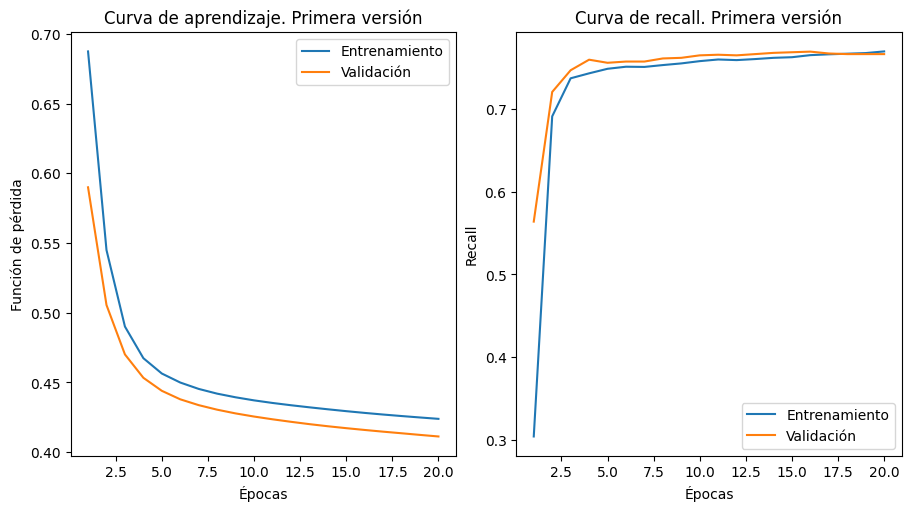

In [ ]:
#Gráficas

import matplotlib.pyplot as plt



#Función de pérdida
epochs = range(1, 21)

fig, ax = plt.subplots(1,2, figsize=(9,5), layout="constrained")
ax[0].plot(epochs, history_version1.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version1.history["val_loss"], label="Validación")

ax[0].set(xlabel="Épocas", ylabel="Función de pérdida", title="Curva de aprendizaje. Primera versión")

ax[0].legend()




ax[1].plot(epochs, history_version1.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version1.history["val_recall"], label="Validación")
ax[1].set(xlabel="Épocas", ylabel="Recall", title="Curva de recall. Primera versión")

ax[1].legend()


plt.show()






84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


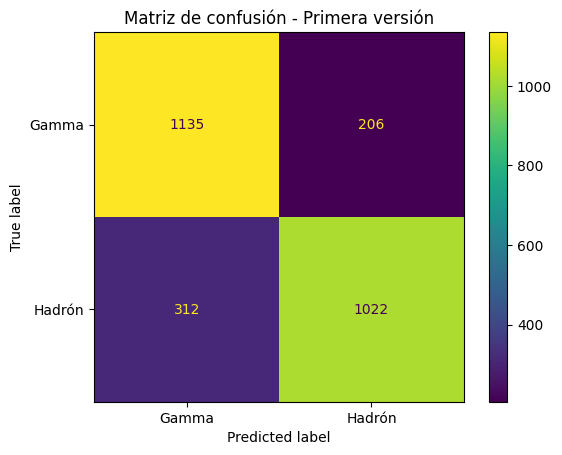

In [ ]:
#Matriz de confusión


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo
Y_val_prob_v1 = version1.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si  >= 0.5, hadrón
# Si  < 0.5, gamma
Y_val_pred_v1 = (Y_val_prob_v1 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v1 = confusion_matrix(np.ravel(Y_val),np.ravel(Y_val_pred_v1))


disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v1,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Primera versión")
plt.show()

In [ ]:
#Se hace una tabla con el objetivo de comparar los modelos


TN_v1, FP_v1, FN_v1, TP_v1 = conf_matrix_v1.ravel()

resultados_modelos = []

resultados_modelos.append({
    "Modelo": "Versión 1",
    "Arquitectura": "Capa Oculta: 1:6 ; Capa salida: 1",
    "Dropout": "No",
    "Early Stopping": "No",
    "Batch size": 40,
    "Épocas": 20,
    "Función de pérdida validación": loss_v1,
    "Accuracy validación": accuracy_v1,
    "Recall validación": recall_v1,
    "TN": TN_v1,
    "FP": FP_v1,
    "FN": FN_v1,
    "TP": TP_v1
})

tabla_modelos = pd.DataFrame(resultados_modelos)
tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.41121,0.806355,0.766117,1135,206,312,1022


Aunque no muestra señales de overfitting, el recall puede mejorarse (identifica correctamente un $76.6\%$ de los hadrones). Se intentará mejorar este aspecto. No obstante, como primera versión se esperaban resultados un tanto peores.




5.  Se aumentará el número de neuronas en capa oculta para observar cómo cambian las métricas


**VERSIÓN 2**

In [ ]:
# Semilla para replicabilidad
tf.random.set_seed(10)

# Modelo 2
version2 = Sequential([
    Input(shape=(6,)),
    Dense(24, activation="relu"),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version2.summary()



# Entrenamiento de la versión 1

history_version2 = version2.fit(X_train_scaled,Y_train,epochs=20,batch_size=40,validation_data=(X_val_scaled, Y_val),verbose=0)

# Evaluación del modelo base en validación

loss_v2, accuracy_v2, recall_v2 = version2.evaluate(X_val_scaled,Y_val,verbose=0)

print("---------------- MÉTRICAS ------------------------")
print("Loss validación:", loss_v2)
print("Accuracy validación:", accuracy_v2)
print("Recall validación:", recall_v2)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 24)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS ------------------------
Loss validación: 0.4017951488494873
Accuracy validación: 0.8112149238586426
Recall validación: 0.7751124501228333


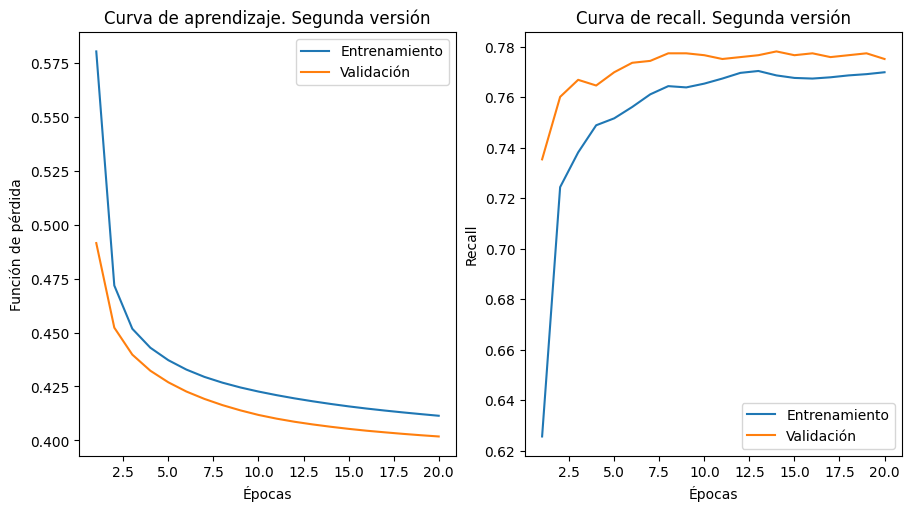

In [ ]:


#Función de pérdida
epochs = range(1, 21)

fig, ax = plt.subplots(1,2, figsize=(9,5), layout="constrained")
ax[0].plot(epochs, history_version2.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version2.history["val_loss"], label="Validación")

ax[0].set(xlabel="Épocas", ylabel="Función de pérdida", title="Curva de aprendizaje. Segunda versión")

ax[0].legend()


#HAcemos plot de las curvas de aprendizaje

ax[1].plot(epochs, history_version2.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version2.history["val_recall"], label="Validación")
ax[1].set(xlabel="Épocas", ylabel="Recall", title="Curva de recall. Segunda versión")

ax[1].legend()


plt.show()



84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


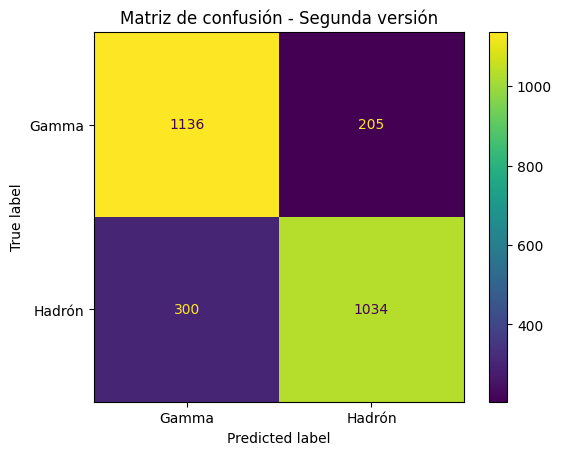

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 2
Y_val_prob_v2 = version2.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v2 = (Y_val_prob_v2 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v2 = confusion_matrix(np.ravel(Y_val),np.ravel(Y_val_pred_v2))

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v2,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Segunda versión")
plt.show()

In [ ]:
#Se hace una tabla con el objetivo de comparar los modelos


TN_v2, FP_v2, FN_v2, TP_v2 = conf_matrix_v2.ravel() #Se extraen los datos de la matriz de confusión

resultados_modelos.append({
    "Modelo": "Versión 2",
    "Arquitectura": "Capa oculta: 1:24 ; Capa salida: 1",
    "Dropout": "No",
    "Early Stopping": "No",
    "Batch size": 40,
    "Épocas": 20,
    "Función de pérdida validación": loss_v2,
    "Accuracy validación": accuracy_v2,
    "Recall validación": recall_v2,
    "TN": TN_v2,
    "FP": FP_v2,
    "FN": FN_v2,
    "TP": TP_v2
})

tabla_modelos = pd.DataFrame(resultados_modelos)
tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034


Tanto accuracy como recall mejoraron. No obstante, la mejora en el recall no fue sustancial, pero se encuentra en la dirección correcta. El overfitting y underfitting siguen controlados, pues las curvas de aprendizaje entre validación y entrenamiento no muestran diferencias sustanciales.

6. Versión 3: se agregará dropout de $0.2$ y una capa oculta


**VERSIÓN 3**

In [ ]:
from tensorflow.keras.layers import Input, Dense, Dropout

# Semilla para replicabilidad
tf.random.set_seed(10)

# Modelo con Dropout
version3 = Sequential([
    Input(shape=(6,)),
    Dense(24, activation="relu"),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version3.summary()


# Entrenamiento de la versión 3

history_version3 = version3.fit(
    X_train_scaled,
    Y_train,
    epochs=20,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    verbose=0
)


# Evaluación del modelo 3 en validación

loss_v3, accuracy_v3, recall_v3 = version3.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS ------------------------")
print("Loss validación:", loss_v3)
print("Accuracy validación:", accuracy_v3)
print("Recall validación:", recall_v3)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 24)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585 (2.29 KB)

 Trainable params: 585 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS ------------------------
Loss validación: 0.3909929096698761
Accuracy validación: 0.8063551187515259
Recall validación: 0.7571214437484741


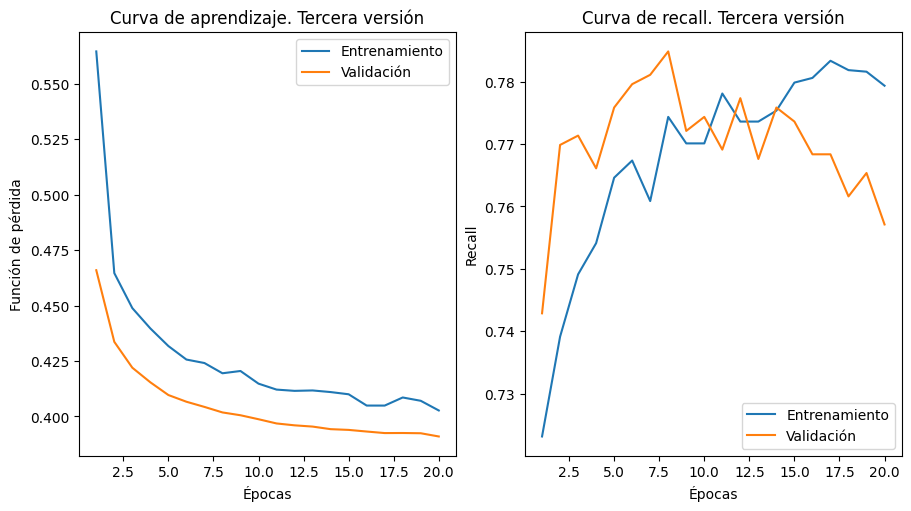

In [ ]:
# Curvas de pérdida y recall

epochs = range(1, 21)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version3.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version3.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Tercera versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version3.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version3.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Tercera versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


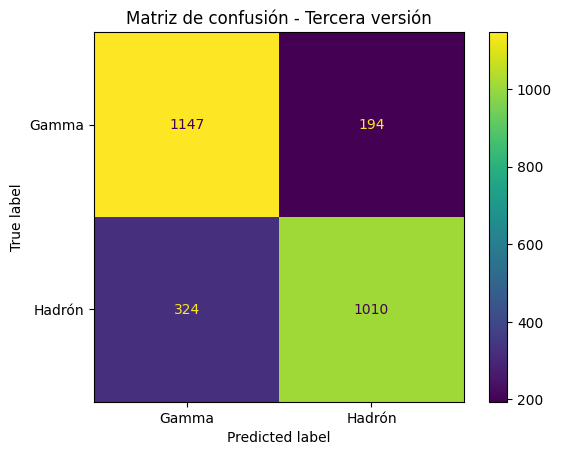

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 3
Y_val_prob_v3 = version3.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v3 = (Y_val_prob_v3 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v3 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v3)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v3,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Tercera versión")
plt.show()

In [ ]:
#Se hace una tabla con el objetivo de comparar los modelos


TN_v3, FP_v3, FN_v3, TP_v3 = conf_matrix_v3.ravel()

resultados_modelos.append({
    "Modelo": "Versión 3",
    "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
    "Dropout": "0.2",
    "Early Stopping": "No",
    "Batch size": 40,
    "Épocas": 20,
    "Función de pérdida validación": loss_v3,
    "Accuracy validación": accuracy_v3,
    "Recall validación": recall_v3,
    "TN": TN_v3,
    "FP": FP_v3,
    "FN": FN_v3,
    "TP": TP_v3
})

tabla_modelos = pd.DataFrame(resultados_modelos)
tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010


Note que el recall empeoró. Esta versión no resulta adecuada. Se buscará otra versión más compleja y, si no funciona, se regresará a las simples.

7. **VERSIÓN 4**

Se buscará aplicar Early Stopping y aumentar el número de Epochs. También aumentaremos el número de neuronas en capa oculta $1$ y reduciremos el dropout a $0.1$.


In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(12)

# Early Stopping
early_stop_v4 = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=12,
    restore_best_weights=True
)

# Modelo 4
version4 = Sequential([
    Input(shape=(6,)),
    Dense(32, activation="relu"),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dropout(0.1),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version4.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version4.summary()

# Entrenamiento de la versión 4
history_version4 = version4.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=32,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v4],
    verbose=0
)

# Evaluación del modelo 4 en validación
loss_v4, accuracy_v4, recall_v4 = version4.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 4 ------------------------")
print("Loss validación:", loss_v4)
print("Accuracy validación:", accuracy_v4)
print("Recall validación:", recall_v4)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 769 (3.00 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 4 ------------------------
Loss validación: 0.37348809838294983
Accuracy validación: 0.8175700902938843
Recall validación: 0.760869562625885


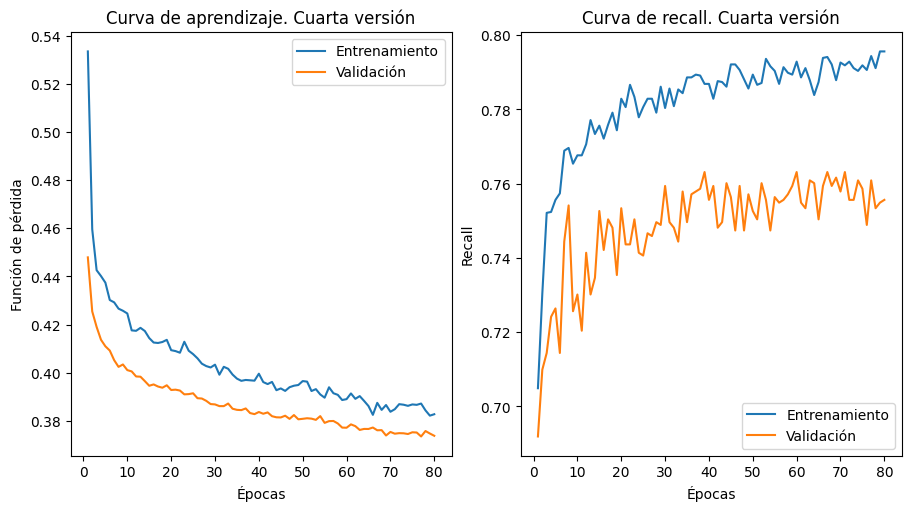

In [ ]:
# Curvas de pérdida y recall - Versión 4

epochs = range(1, len(history_version4.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version4.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version4.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Cuarta versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version4.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version4.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Cuarta versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


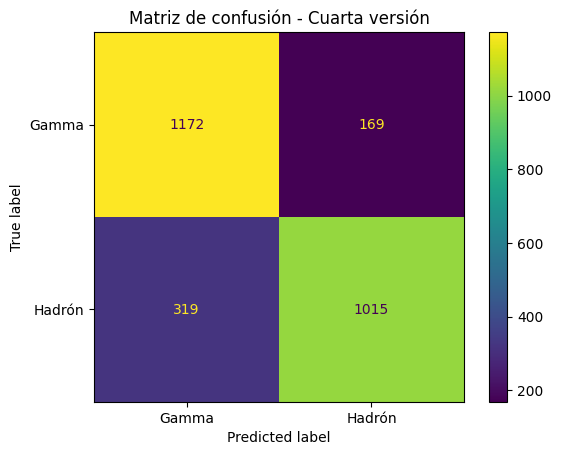

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 4
Y_val_prob_v4 = version4.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v4 = (Y_val_prob_v4 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v4 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v4)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v4,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Cuarta versión")
plt.show()

In [ ]:
#Hacemos tabla para comparar versiones

TN_v4, FP_v4, FN_v4, TP_v4 = conf_matrix_v4.ravel()

resultados_modelos.append({
    "Modelo": "Versión 4",
    "Arquitectura": "Capas ocultas: 1:32, 1:16 ; Capa salida: 1",
    "Dropout": "Sí, 0.1 y 0.1",
    "Early Stopping": "Sí",
    "Batch size": 32,
    "Épocas": len(history_version4.history["loss"]),
    "Función de pérdida validación": loss_v4,
    "Accuracy validación": accuracy_v4,
    "Recall validación": recall_v4,
    "TN": TN_v4,
    "FP": FP_v4,
    "FN": FN_v4,
    "TP": TP_v4
})

tabla_modelos = pd.DataFrame(resultados_modelos)
tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015


Pese a que mejora con respecto al modelo anterior, el resultado no es sustancialmente diferente. Se optará por versiones un poco más sencillas. Debe resaltarse que los accuracy se han mantenido estables.




8. **VERSIÓN 5**

Probaremos quitar el dropout y reducir el número de epochs

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(12)

# Early Stopping
early_stop_v5 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 5
version5 = Sequential([
    Input(shape=(6,)),
    Dense(24, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version5.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version5.summary()


# Entrenamiento de la versión 5
history_version5 = version5.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=32,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v5],
    verbose=0
)

# Evaluación del modelo 5 en validación
loss_v5, accuracy_v5, recall_v5 = version5.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 5 ------------------------")
print("Loss validación:", loss_v5)
print("Accuracy validación:", accuracy_v5)
print("Recall validación:", recall_v5)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 24)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585 (2.29 KB)

 Trainable params: 585 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 5 ------------------------
Loss validación: 0.38206592202186584
Accuracy validación: 0.8157009482383728
Recall validación: 0.7638680934906006


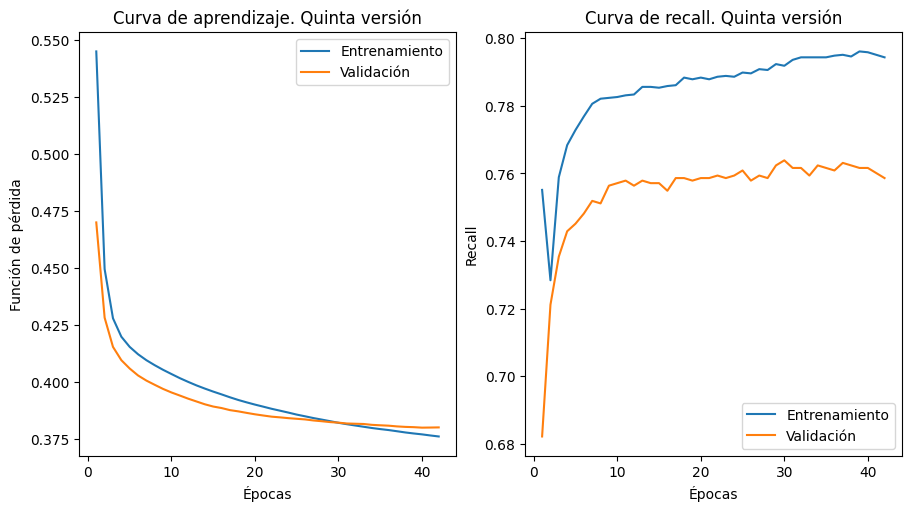

In [ ]:
# Curvas de pérdida y recall - Versión 5

epochs = range(1, len(history_version5.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version5.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version5.history["val_loss"], label="Validación")

ax[0].set(xlabel="Épocas",ylabel="Función de pérdida",title="Curva de aprendizaje. Quinta versión")

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version5.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version5.history["val_recall"], label="Validación")

ax[1].set(xlabel="Épocas",ylabel="Recall",title="Curva de recall. Quinta versión")

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


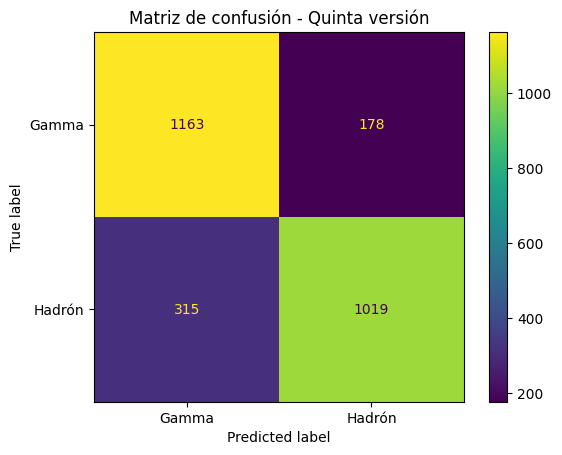

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 5
Y_val_prob_v5 = version5.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v5 = (Y_val_prob_v5 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v5 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v5,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Quinta versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v5, FP_v5, FN_v5, TP_v5 = conf_matrix_v5.ravel()

# Agregar resultados de la versión 5 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 5",
    "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
    "Dropout": "No",
    "Early Stopping": "Sí",
    "Batch size": 32,
    "Épocas": len(history_version5.history["loss"]),
    "Función de pérdida validación": loss_v5,
    "Accuracy validación": accuracy_v5,
    "Recall validación": recall_v5,
    "TN": TN_v5,
    "FP": FP_v5,
    "FN": FN_v5,
    "TP": TP_v5
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019


Probaremos con dropout a ver si algo mejora. El accuracy aumentó y el recall aumentó.

9. **VERSIÓN 6**

In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(12)

# Early Stopping
early_stop_v6 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 6
version6 = Sequential([
    Input(shape=(6,)),
    Dense(24, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version6.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version6.summary()


# Entrenamiento de la versión 6
history_version6 = version6.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=32,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v6],
    verbose=0
)

# Evaluación del modelo 6 en validación
loss_v6, accuracy_v6, recall_v6 = version6.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 6 ------------------------")
print("Loss validación:", loss_v6)
print("Accuracy validación:", accuracy_v6)
print("Recall validación:", recall_v6)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 24)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585 (2.29 KB)

 Trainable params: 585 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 6 ------------------------
Loss validación: 0.4213947057723999
Accuracy validación: 0.8007476925849915
Recall validación: 0.7856072187423706


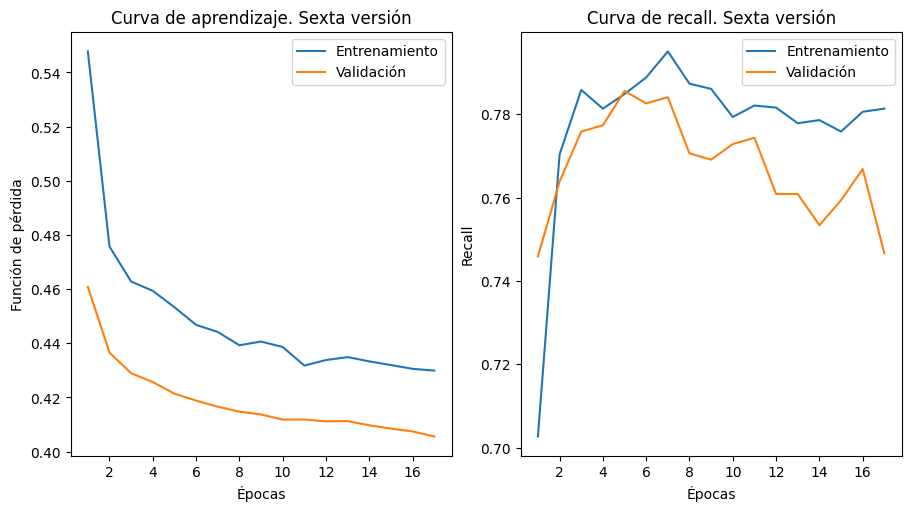

In [ ]:

epochs = range(1, len(history_version6.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version6.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version6.history["val_loss"], label="Validación")

ax[0].set(xlabel="Épocas",ylabel="Función de pérdida",title="Curva de aprendizaje. Sexta versión")

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version6.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version6.history["val_recall"], label="Validación")

ax[1].set(xlabel="Épocas",ylabel="Recall",title="Curva de recall. Sexta versión")

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


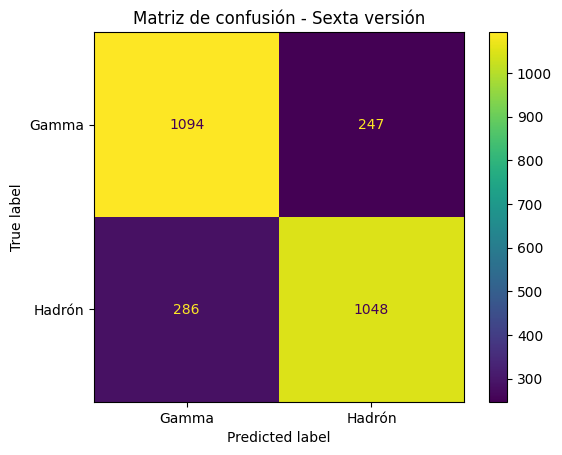

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 6
Y_val_prob_v6 = version6.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v6 = (Y_val_prob_v6 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v6 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v6,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Sexta versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v6, FP_v6, FN_v6, TP_v6 = conf_matrix_v6.ravel()

# Agregar resultados de la versión 6 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 6",
    "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
    "Dropout": "Sí, 0.2 y 0.2",
    "Early Stopping": "Sí",
    "Batch size": 32,
    "Épocas": len(history_version6.history["loss"]),
    "Función de pérdida validación": loss_v6,
    "Accuracy validación": accuracy_v6,
    "Recall validación": recall_v6,
    "TN": TN_v6,
    "FP": FP_v6,
    "FN": FN_v6,
    "TP": TP_v6
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048


Mejoró el recall, aunque la función de pérdida no se minimizó tanto. Se ajustará lo siguiente: aumentaremos el batch size para ser más coherentes con los primeros modelos y mantendremos el dropout en $0.2$ para ver qué sucede.

10. **VERSIÓN 7**

In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(12)

# Early Stopping
early_stop_v7 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 7
version7 = Sequential([
    Input(shape=(6,)),
    Dense(24, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version7.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version7.summary()


# Entrenamiento de la versión 7
history_version7 = version7.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v7],
    verbose=0
)

# Evaluación del modelo 7 en validación
loss_v7, accuracy_v7, recall_v7 = version7.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 7 ------------------------")
print("Loss validación:", loss_v7)
print("Accuracy validación:", accuracy_v7)
print("Recall validación:", recall_v7)

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 24)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585 (2.29 KB)

 Trainable params: 585 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 7 ------------------------
Loss validación: 0.40591609477996826
Accuracy validación: 0.8044859766960144
Recall validación: 0.7721139192581177


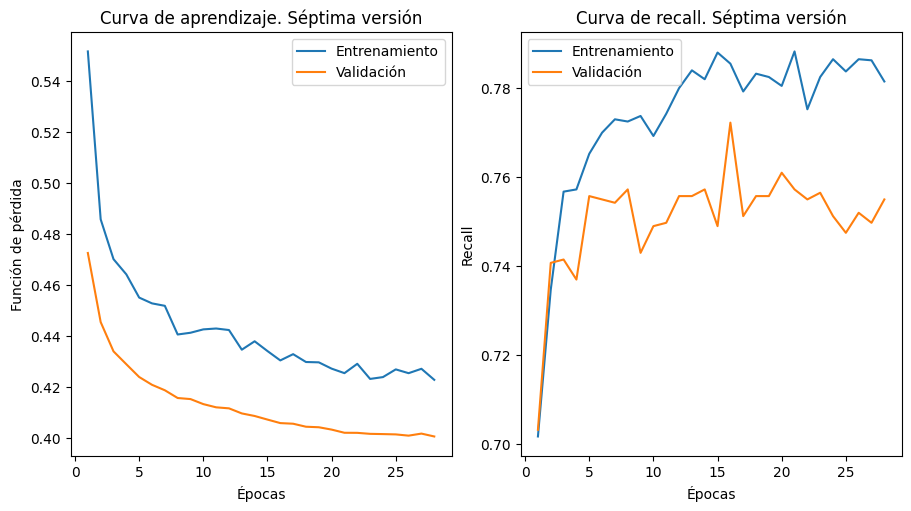

In [ ]:
# Curvas de pérdida y recall - Versión 7

epochs = range(1, len(history_version7.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version7.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version7.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Séptima versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version7.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version7.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Séptima versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


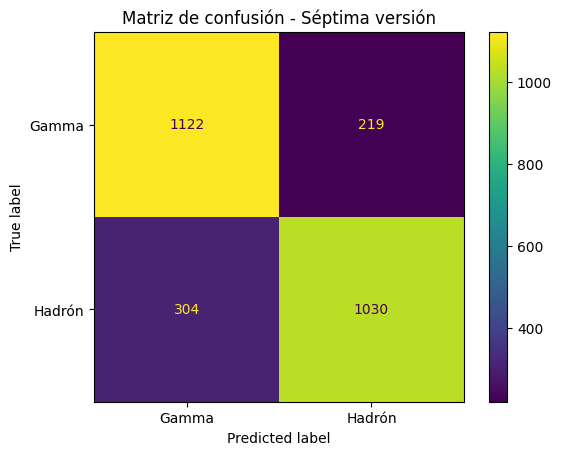

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 7
Y_val_prob_v7 = version7.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v7 = (Y_val_prob_v7 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v7 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v7)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v7,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Séptima versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v7, FP_v7, FN_v7, TP_v7 = conf_matrix_v7.ravel()


# Agregar resultados de la versión 7 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 7",
    "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
    "Dropout": "Sí, 0.2 y 0.2",
    "Early Stopping": "Sí",
    "Batch size": 40,
    "Épocas": len(history_version7.history["loss"]),
    "Función de pérdida validación": loss_v7,
    "Accuracy validación": accuracy_v7,
    "Recall validación": recall_v7,
    "TN": TN_v7,
    "FP": FP_v7,
    "FN": FN_v7,
    "TP": TP_v7
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030


La versión 6 sigue siendo la mejor. Probaremos modificando la métrica de early stopping por la función de pérdida.

11. **VERSIÓN 8**

In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(12)

# Early Stopping
early_stop_v8 = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=12,
    restore_best_weights=True
)

# Modelo 8
version8 = Sequential([
    Input(shape=(6,)),
    Dense(24, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version8.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version8.summary()


# Entrenamiento de la versión 8
history_version8 = version8.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v8],
    verbose=0
)

# Evaluación del modelo 8 en validación
loss_v8, accuracy_v8, recall_v8 = version8.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 8 ------------------------")
print("Loss validación:", loss_v8)
print("Accuracy validación:", accuracy_v8)
print("Recall validación:", recall_v8)

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 24)             │           168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585 (2.29 KB)

 Trainable params: 585 (2.29 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 8 ------------------------
Loss validación: 0.38108399510383606
Accuracy validación: 0.8168224096298218
Recall validación: 0.7773613333702087


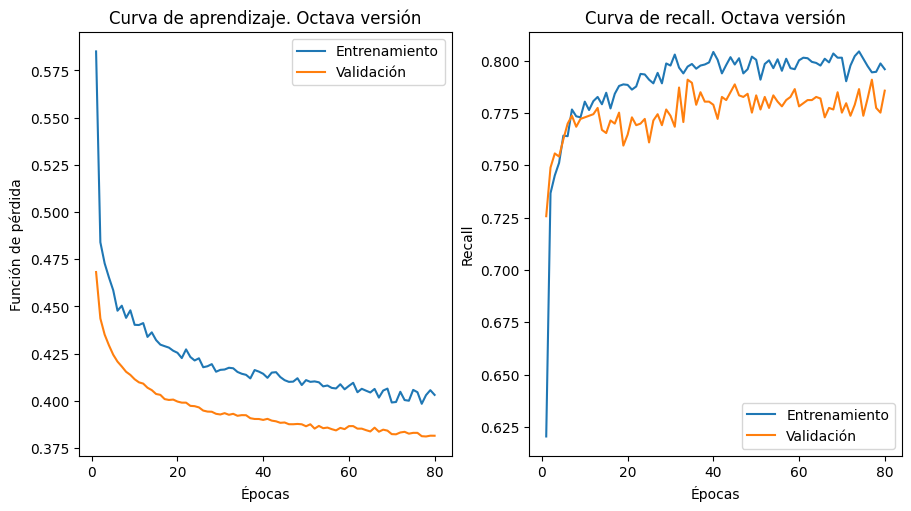

In [ ]:
# Curvas de pérdida y recall - Versión 8

epochs = range(1, len(history_version8.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version8.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version8.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Octava versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version8.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version8.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Octava versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


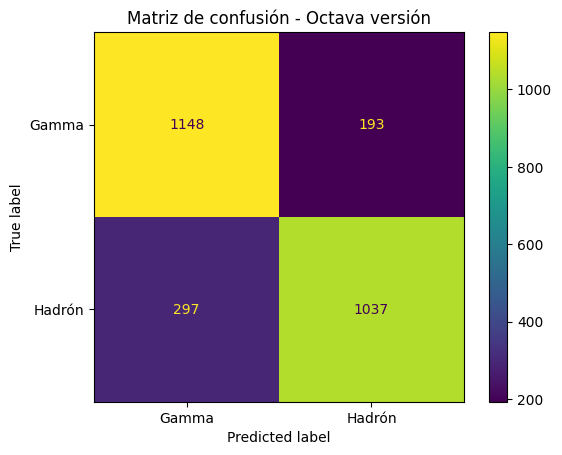

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 8
Y_val_prob_v8 = version8.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v8 = (Y_val_prob_v8 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v8 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v8,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Octava versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v8, FP_v8, FN_v8, TP_v8 = conf_matrix_v8.ravel()

# Agregar resultados de la versión 8 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 8",
    "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
    "Dropout": "Sí, 0.2 y 0.2",
    "Early Stopping": "Sí",
    "Batch size": 40,
    "Épocas": len(history_version8.history["loss"]),
    "Función de pérdida validación": loss_v8,
    "Accuracy validación": accuracy_v8,
    "Recall validación": recall_v8,
    "TN": TN_v8,
    "FP": FP_v8,
    "FN": FN_v8,
    "TP": TP_v8
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030
7,Versión 8,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,80,0.381084,0.816822,0.777361,1148,193,297,1037


Trataremos de simplificar un poco el modelo para ver si suceden cambios que podamos valorar en cuanto al recall, pues estos modelos han tenido desempeños medianamente estables. En particular los cambios que haremos serán los siguientes: volveremos al batch size de 32 siguiendo el resultado de recall en el modelo 6; reduciremos el número de neuronas para ver si, con menos complejidad, se obtienen resultados relevantes; por último, se ajustarán las épocas manualmente antes de presentar la versión final de la 9 en este notebook

12. **VERSIÓN 9**




In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
import random
import numpy as np



# Semilla para replicabilidad

tf.random.set_seed(20)

# Early Stopping
early_stop_v9 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 9
version9 = Sequential([
    Input(shape=(6,)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version9.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version9.summary()


# Entrenamiento de la versión 9
history_version9 = version9.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=32,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v9],
    verbose=0
)

# Evaluación del modelo 9 en validación
loss_v9, accuracy_v9, recall_v9 = version9.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 9 ------------------------")
print("Loss validación:", loss_v9)
print("Accuracy validación:", accuracy_v9)
print("Recall validación:", recall_v9)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 9 ------------------------
Loss validación: 0.401608407497406
Accuracy validación: 0.8007476925849915
Recall validación: 0.8373313546180725


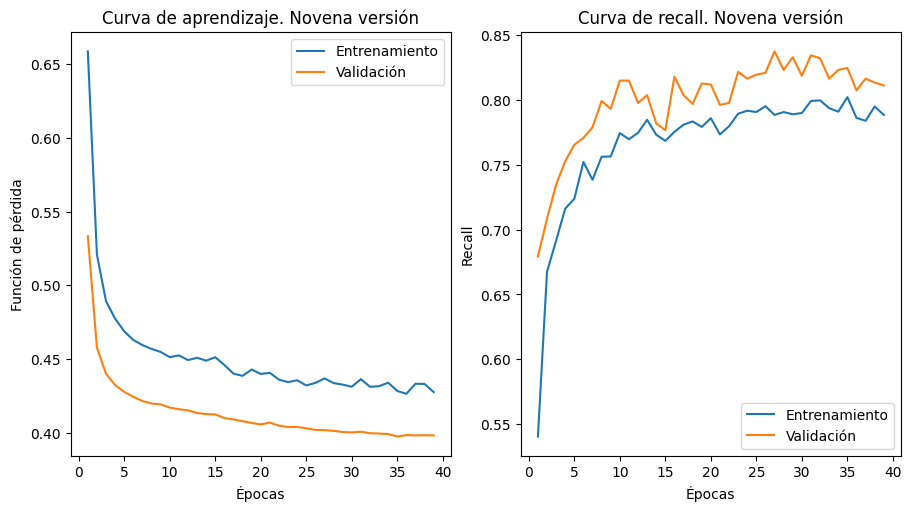

In [ ]:
# Curvas de pérdida y recall - Versión 9

epochs = range(1, len(history_version9.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version9.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version9.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Novena versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version9.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version9.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Novena versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


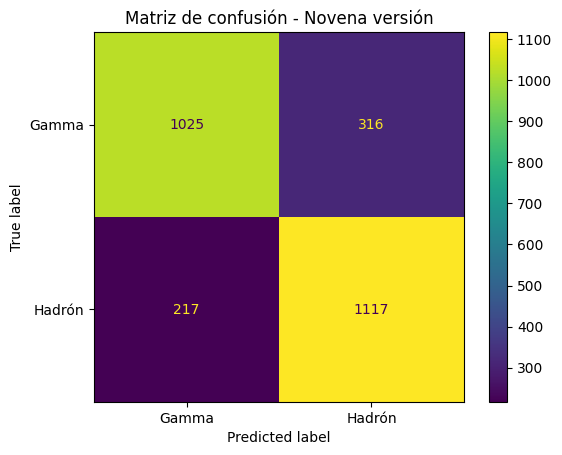

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 9
Y_val_prob_v9 = version9.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v9 = (Y_val_prob_v9 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v9 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v9)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v9,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Novena versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v9, FP_v9, FN_v9, TP_v9 = conf_matrix_v9.ravel()

# Agregar resultados de la versión 9 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 9",
    "Arquitectura": "Capas ocultas: 1:16, 1:8 ; Capa salida: 1",
    "Dropout": "Sí, 0.2 y 0.2",
    "Early Stopping": "Sí",
    "Batch size": 32,
    "Épocas": len(history_version9.history["loss"]),
    "Función de pérdida validación": loss_v9,
    "Accuracy validación": accuracy_v9,
    "Recall validación": recall_v9,
    "TN": TN_v9,
    "FP": FP_v9,
    "FN": FN_v9,
    "TP": TP_v9
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030
7,Versión 8,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,80,0.381084,0.816822,0.777361,1148,193,297,1037
8,Versión 9,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,39,0.401608,0.800748,0.837331,1025,316,217,1117


El modelo obtuvo un recall de validación de $0.8373$, que es sustancialmente alto a los demás modelos. Aunque no es el accuracy más alto entre todos los modelos, sigue siendo un buen valor. Las curvas de aprendizaje muestran que la pérdida de entrenamiento y validación disminuyen durante las épocas. No hay indicios de sobreajuste ni subajuste. Este es el mejor modelo que se ha obtenido. Se probarán algunas otras versiones para observar si se tiene alguna mejora.

13. **VERSIÓN 10**

In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(20)

# Early Stopping
early_stop_v10 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 10
version10 = Sequential([
    Input(shape=(6,)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version10.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version10.summary()


# Entrenamiento de la versión 10
history_version10 = version10.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=20,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v10],
    verbose=0
)

# Evaluación del modelo 10 en validación
loss_v10, accuracy_v10, recall_v10 = version10.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 10 ------------------------")
print("Loss validación:", loss_v10)
print("Accuracy validación:", accuracy_v10)
print("Recall validación:", recall_v10)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 10 ------------------------
Loss validación: 0.4130210876464844
Accuracy validación: 0.8115887641906738
Recall validación: 0.7901049256324768


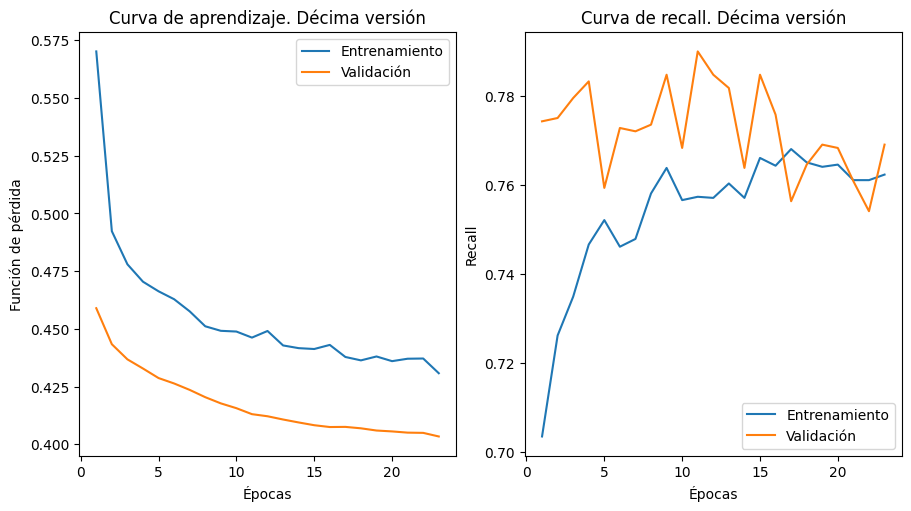

In [ ]:
# Curvas de pérdida y recall - Versión 10

epochs = range(1, len(history_version10.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version10.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version10.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Décima versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version10.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version10.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Décima versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


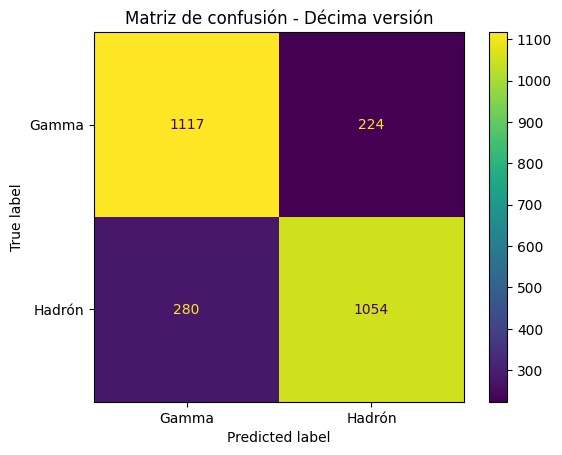

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030
7,Versión 8,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,80,0.381084,0.816822,0.777361,1148,193,297,1037
8,Versión 9,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,39,0.401608,0.800748,0.837331,1025,316,217,1117
9,Versión 10,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,20,23,0.413021,0.811589,0.790105,1117,224,280,1054


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 10
Y_val_prob_v10 = version10.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v10 = (Y_val_prob_v10 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v10 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v10)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v10,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Décima versión")
plt.show()

# Extraer valores de la matriz de confusión

TN_v10, FP_v10, FN_v10, TP_v10 = conf_matrix_v10.ravel()

# Agregar resultados de la versión 10 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 10",
    "Arquitectura": "Capas ocultas: 1:16, 1:8 ; Capa salida: 1",
    "Dropout": "Sí, 0.2 y 0.2",
    "Early Stopping": "Sí",
    "Batch size": 20,
    "Épocas": len(history_version10.history["loss"]),
    "Función de pérdida validación": loss_v10,
    "Accuracy validación": accuracy_v10,
    "Recall validación": recall_v10,
    "TN": TN_v10,
    "FP": FP_v10,
    "FN": FN_v10,
    "TP": TP_v10
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

Se evidencia un recall en validación menor. Se explorarán otras opciones alrededor del modelo 9.

14. **VERSIÓN 11**

In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla para replicabilidad
tf.random.set_seed(20)

# Early Stopping
early_stop_v11 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 11
version11 = Sequential([
    Input(shape=(6,)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version11.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version11.summary()


# Entrenamiento de la versión 11
history_version11 = version11.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=32,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v11],
    verbose=0
)

# Evaluación del modelo 11 en validación
loss_v11, accuracy_v11, recall_v11 = version11.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 11 ------------------------")
print("Loss validación:", loss_v11)
print("Accuracy validación:", accuracy_v11)
print("Recall validación:", recall_v11)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           170 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293 (1.14 KB)

 Trainable params: 293 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 11 ------------------------
Loss validación: 0.39605793356895447
Accuracy validación: 0.816074788570404
Recall validación: 0.7968515753746033


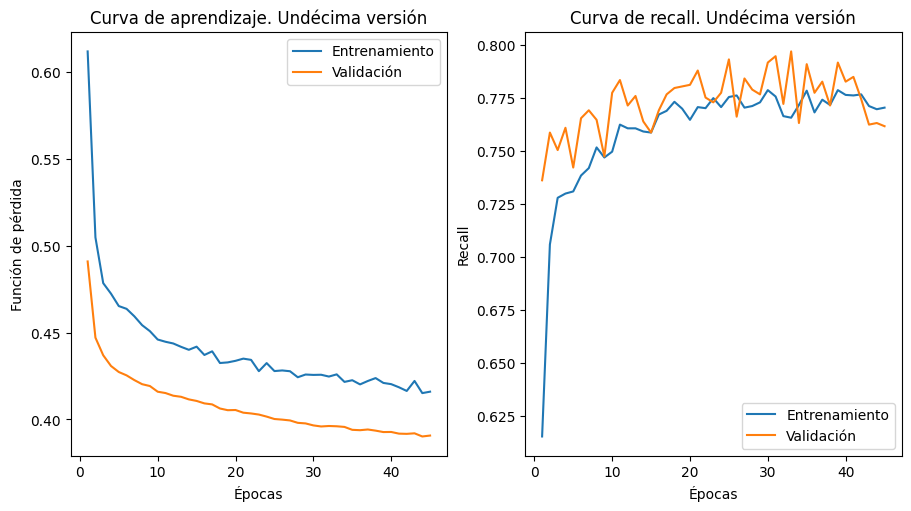

In [ ]:
# Curvas de pérdida y recall - Versión 11

epochs = range(1, len(history_version11.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version11.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version11.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Undécima versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version11.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version11.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Undécima versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


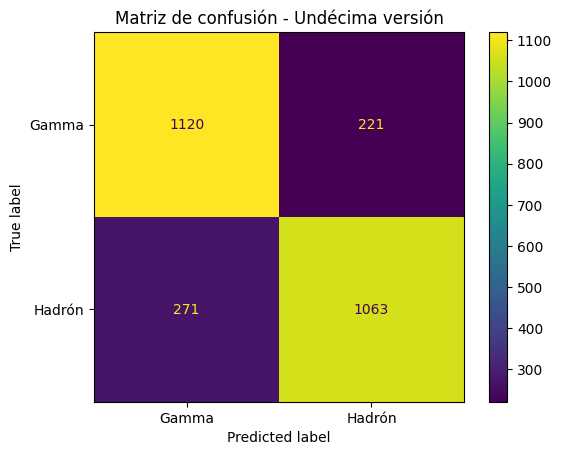

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 11
Y_val_prob_v11 = version11.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v11 = (Y_val_prob_v11 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v11 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v11)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v11,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Undécima versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v11, FP_v11, FN_v11, TP_v11 = conf_matrix_v11.ravel()

# Agregar resultados de la versión 11 a la tabla

resultados_modelos.append({
    "Modelo": "Versión 11",
    "Arquitectura": "Capas ocultas: 1:16, 1:10 ; Capa salida: 1",
    "Dropout": "Sí, 0.2 y 0.2",
    "Early Stopping": "Sí",
    "Batch size": 32,
    "Épocas": len(history_version11.history["loss"]),
    "Función de pérdida validación": loss_v11,
    "Accuracy validación": accuracy_v11,
    "Recall validación": recall_v11,
    "TN": TN_v11,
    "FP": FP_v11,
    "FN": FN_v11,
    "TP": TP_v11
})

tabla_modelos = pd.DataFrame(resultados_modelos)

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa Oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030
7,Versión 8,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,80,0.381084,0.816822,0.777361,1148,193,297,1037
8,Versión 9,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,39,0.401608,0.800748,0.837331,1025,316,217,1117
9,Versión 10,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,20,23,0.413021,0.811589,0.790105,1117,224,280,1054


El recall no mejoró sustancialmente. La mejor versión sigue siendo la número 9. Se trabajará sobre ella para ver qué podemos cambiar.



**VERSIÓN 12** (MODELO GRANDE)

Intentaremos modelos más grandes para ver si hay alguna mejora.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# Semilla para replicabilidad
tf.random.set_seed(20)

# Early Stopping
early_stop_grande = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo grande
modelo_grande = Sequential([
    Input(shape=(6,)),
    Dense(1024, activation="relu"),
    Dropout(0.5),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

modelo_grande.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

modelo_grande.summary()


# Entrenamiento del modelo grande
history_modelo_grande = modelo_grande.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_grande],
    verbose=0
)

# Evaluación del modelo grande en validación
loss_grande, accuracy_grande, recall_grande = modelo_grande.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS MODELO GRANDE ------------------------")
print("Loss validación:", loss_grande)
print("Accuracy validación:", accuracy_grande)
print("Recall validación:", recall_grande)

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_84 (Dense)                │ (None, 1024)           │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_70 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_71 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_72 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_73 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_88 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_74 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_89 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 704,513 (2.69 MB)

 Trainable params: 704,513 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS MODELO GRANDE ------------------------
Loss validación: 0.4251575171947479
Accuracy validación: 0.7955140471458435
Recall validación: 0.8268365859985352


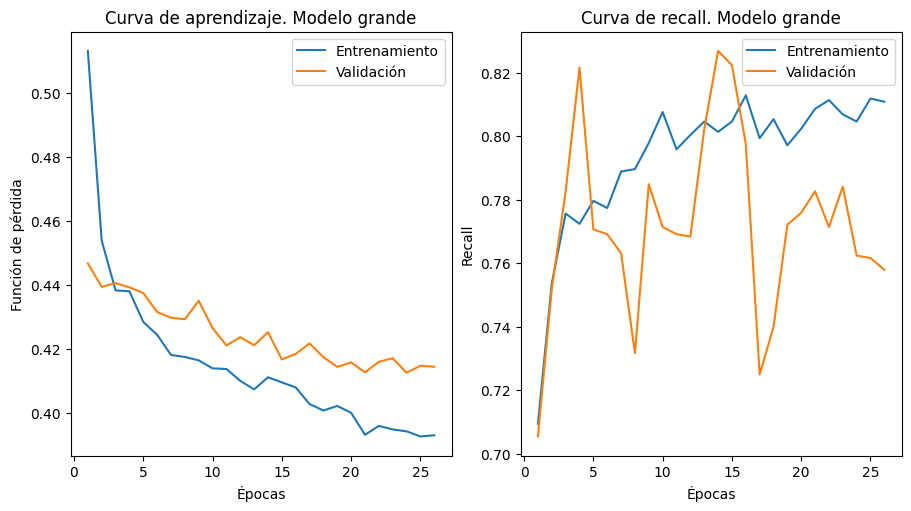

In [ ]:
# Curvas de pérdida y recall - Versión 12

# Curvas de pérdida y recall - Modelo grande

import matplotlib.pyplot as plt

epochs = range(1, len(history_modelo_grande.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_modelo_grande.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_modelo_grande.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Modelo grande"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_modelo_grande.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_modelo_grande.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Modelo grande"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


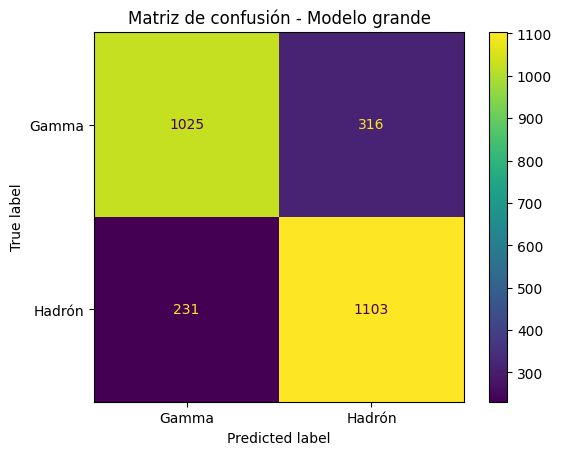

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo grande
Y_val_prob_grande = modelo_grande.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_grande = (Y_val_prob_grande >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_grande = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_grande)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_grande,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Modelo grande")
plt.show()

In [ ]:
# Agregar modelo grande como Versión 12 a la tabla

TN_grande, FP_grande, FN_grande, TP_grande = conf_matrix_grande.ravel()

#Reconstruimos la tabla porque se borró de memoria
tabla_modelos = pd.DataFrame([
    {
        "Modelo": "Versión 1",
        "Arquitectura": "Capa oculta: 1:6 ; Capa salida: 1",
        "Dropout": "No",
        "Early Stopping": "No",
        "Batch size": 40,
        "Épocas": 20,
        "Función de pérdida validación": 0.411210,
        "Accuracy validación": 0.806355,
        "Recall validación": 0.766117,
        "TN": 1135,
        "FP": 206,
        "FN": 312,
        "TP": 1022
    },
    {
        "Modelo": "Versión 2",
        "Arquitectura": "Capa oculta: 1:24 ; Capa salida: 1",
        "Dropout": "No",
        "Early Stopping": "No",
        "Batch size": 40,
        "Épocas": 20,
        "Función de pérdida validación": 0.401795,
        "Accuracy validación": 0.811215,
        "Recall validación": 0.775112,
        "TN": 1136,
        "FP": 205,
        "FN": 300,
        "TP": 1034
    },
    {
        "Modelo": "Versión 3",
        "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
        "Dropout": "0.2",
        "Early Stopping": "No",
        "Batch size": 40,
        "Épocas": 20,
        "Función de pérdida validación": 0.390993,
        "Accuracy validación": 0.806355,
        "Recall validación": 0.757121,
        "TN": 1147,
        "FP": 194,
        "FN": 324,
        "TP": 1010
    },
    {
        "Modelo": "Versión 4",
        "Arquitectura": "Capas ocultas: 1:32, 1:16 ; Capa salida: 1",
        "Dropout": "Sí, 0.1 y 0.1",
        "Early Stopping": "Sí",
        "Batch size": 32,
        "Épocas": 80,
        "Función de pérdida validación": 0.373488,
        "Accuracy validación": 0.817570,
        "Recall validación": 0.760870,
        "TN": 1172,
        "FP": 169,
        "FN": 319,
        "TP": 1015
    },
    {
        "Modelo": "Versión 5",
        "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
        "Dropout": "No",
        "Early Stopping": "Sí",
        "Batch size": 32,
        "Épocas": 42,
        "Función de pérdida validación": 0.382066,
        "Accuracy validación": 0.815701,
        "Recall validación": 0.763868,
        "TN": 1163,
        "FP": 178,
        "FN": 315,
        "TP": 1019
    },
    {
        "Modelo": "Versión 6",
        "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
        "Dropout": "Sí, 0.2 y 0.2",
        "Early Stopping": "Sí",
        "Batch size": 32,
        "Épocas": 17,
        "Función de pérdida validación": 0.421395,
        "Accuracy validación": 0.800748,
        "Recall validación": 0.785607,
        "TN": 1094,
        "FP": 247,
        "FN": 286,
        "TP": 1048
    },
    {
        "Modelo": "Versión 7",
        "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
        "Dropout": "Sí, 0.2 y 0.2",
        "Early Stopping": "Sí",
        "Batch size": 40,
        "Épocas": 28,
        "Función de pérdida validación": 0.405916,
        "Accuracy validación": 0.804486,
        "Recall validación": 0.772114,
        "TN": 1122,
        "FP": 219,
        "FN": 304,
        "TP": 1030
    },
    {
        "Modelo": "Versión 8",
        "Arquitectura": "Capas ocultas: 1:24, 1:16 ; Capa salida: 1",
        "Dropout": "Sí, 0.2 y 0.2",
        "Early Stopping": "Sí",
        "Batch size": 40,
        "Épocas": 80,
        "Función de pérdida validación": 0.381084,
        "Accuracy validación": 0.816822,
        "Recall validación": 0.777361,
        "TN": 1148,
        "FP": 193,
        "FN": 297,
        "TP": 1037
    },
    {
        "Modelo": "Versión 9",
        "Arquitectura": "Capas ocultas: 1:16, 1:8 ; Capa salida: 1",
        "Dropout": "Sí, 0.2 y 0.2",
        "Early Stopping": "Sí",
        "Batch size": 32,
        "Épocas": 39,
        "Función de pérdida validación": 0.401608,
        "Accuracy validación": 0.800748,
        "Recall validación": 0.837331,
        "TN": 1025,
        "FP": 316,
        "FN": 217,
        "TP": 1117
    },
    {
        "Modelo": "Versión 10",
        "Arquitectura": "Capas ocultas: 1:16, 1:8 ; Capa salida: 1",
        "Dropout": "Sí, 0.2 y 0.2",
        "Early Stopping": "Sí",
        "Batch size": 20,
        "Épocas": 23,
        "Función de pérdida validación": 0.413021,
        "Accuracy validación": 0.811589,
        "Recall validación": 0.790105,
        "TN": 1117,
        "FP": 224,
        "FN": 280,
        "TP": 1054
    },
    {
        "Modelo": "Versión 11",
        "Arquitectura": "Capas ocultas: 1:16, 1:10 ; Capa salida: 1",
        "Dropout": "Sí, 0.2 y 0.2",
        "Early Stopping": "Sí",
        "Batch size": 32,
        "Épocas": 45,
        "Función de pérdida validación": 0.396058,
        "Accuracy validación": 0.816075,
        "Recall validación": 0.796852,
        "TN": 1120,
        "FP": 221,
        "FN": 271,
        "TP": 1063
    }
])


tabla_modelos.loc[len(tabla_modelos)] = {
    "Modelo": "Versión 12",
    "Arquitectura": "Capas ocultas: 1:1024, 1:512, 1:256, 1:128, 1:64 ; Capa salida: 1",
    "Dropout": "Sí, 0.5 en todas las capas ocultas",
    "Early Stopping": "Sí",
    "Batch size": 40,
    "Épocas": len(history_modelo_grande.history["loss"]),
    "Función de pérdida validación": loss_grande,
    "Accuracy validación": accuracy_grande,
    "Recall validación": recall_grande,
    "TN": TN_grande,
    "FP": FP_grande,
    "FN": FN_grande,
    "TP": TP_grande
}

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030
7,Versión 8,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,80,0.381084,0.816822,0.777361,1148,193,297,1037
8,Versión 9,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,39,0.401608,0.800748,0.837331,1025,316,217,1117
9,Versión 10,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,20,23,0.413021,0.811589,0.790105,1117,224,280,1054


Este modelo evidencia un recall cercano al de la versión 9; si bien el recall salió por debajo, comparado con otros modelos de pocas neuronas puede que el dato de la versión 9 haya sido alto por pura aleatoriedad. Se comparará con otros modelos grandes parecidos para ver si consistentemente se obtienen recalls elevados.

**VERSIÓN 13**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# Semilla para replicabilidad
tf.random.set_seed(20)

# Early Stopping
early_stop_v13 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 13
version13 = Sequential([
    Input(shape=(6,)),
    Dense(1024, activation="relu"),
    Dropout(0.5),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version13.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version13.summary()


# Entrenamiento de la versión 13
history_version13 = version13.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v13],
    verbose=0
)

# Evaluación del modelo 13 en validación
loss_v13, accuracy_v13, recall_v13 = version13.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 13 ------------------------")
print("Loss validación:", loss_v13)
print("Accuracy validación:", accuracy_v13)
print("Recall validación:", recall_v13)

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_90 (Dense)                │ (None, 1024)           │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_75 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_91 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_76 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_92 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_77 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_93 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_78 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_94 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 696,321 (2.66 MB)

 Trainable params: 696,321 (2.66 MB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 13 ------------------------
Loss validación: 0.4243285357952118
Accuracy validación: 0.8003738522529602
Recall validación: 0.8110944628715515


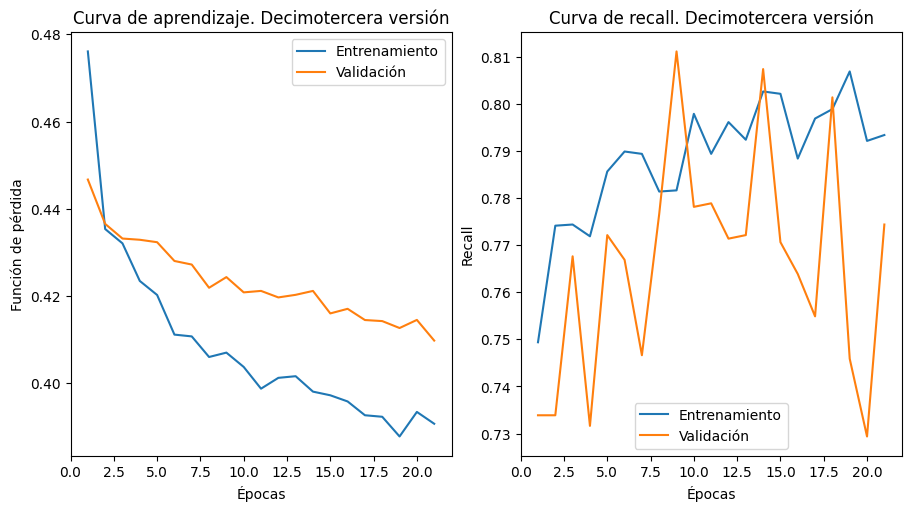

In [ ]:
# Curvas de pérdida y recall - Versión 13

import matplotlib.pyplot as plt

epochs = range(1, len(history_version13.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version13.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version13.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Decimotercera versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version13.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version13.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Decimotercera versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


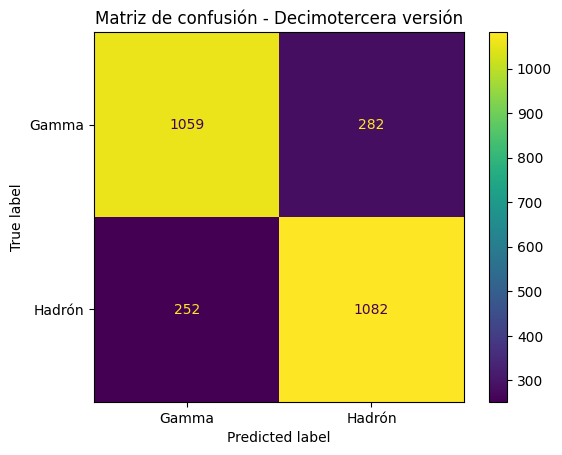

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 13
Y_val_prob_v13 = version13.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v13 = (Y_val_prob_v13 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v13 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v13)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v13,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Decimotercera versión")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_v13, FP_v13, FN_v13, TP_v13 = conf_matrix_v13.ravel()
# Agregar resultados de la versión 13 a la tabla

tabla_modelos.loc[len(tabla_modelos)] = {
    "Modelo": "Versión 13",
    "Arquitectura": "Capas ocultas: 1:1024, 1:512, 1:256, 1:128 ; Capa salida: 1",
    "Dropout": "Sí, 0.5 en todas las capas ocultas",
    "Early Stopping": "Sí",
    "Batch size": 40,
    "Épocas": len(history_version13.history["loss"]),
    "Función de pérdida validación": loss_v13,
    "Accuracy validación": accuracy_v13,
    "Recall validación": recall_v13,
    "TN": TN_v13,
    "FP": FP_v13,
    "FN": FN_v13,
    "TP": TP_v13
}

tabla_modelos

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
0,Versión 1,Capa oculta: 1:6 ; Capa salida: 1,No,No,40,20,0.411210,0.806355,0.766117,1135,206,312,1022
1,Versión 2,Capa oculta: 1:24 ; Capa salida: 1,No,No,40,20,0.401795,0.811215,0.775112,1136,205,300,1034
2,Versión 3,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",0.2,No,40,20,0.390993,0.806355,0.757121,1147,194,324,1010
3,Versión 4,"Capas ocultas: 1:32, 1:16 ; Capa salida: 1","Sí, 0.1 y 0.1",Sí,32,80,0.373488,0.817570,0.760870,1172,169,319,1015
4,Versión 5,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1",No,Sí,32,42,0.382066,0.815701,0.763868,1163,178,315,1019
5,Versión 6,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,17,0.421395,0.800748,0.785607,1094,247,286,1048
6,Versión 7,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,28,0.405916,0.804486,0.772114,1122,219,304,1030
7,Versión 8,"Capas ocultas: 1:24, 1:16 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,40,80,0.381084,0.816822,0.777361,1148,193,297,1037
8,Versión 9,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,32,39,0.401608,0.800748,0.837331,1025,316,217,1117
9,Versión 10,"Capas ocultas: 1:16, 1:8 ; Capa salida: 1","Sí, 0.2 y 0.2",Sí,20,23,0.413021,0.811589,0.790105,1117,224,280,1054


Nuevamente se obtuvo un recall por encima de $0.8$, aunque ligeramente peor. Se probará un modelo más.

**VERSIÓN 14**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

# Semilla para replicabilidad
tf.random.set_seed(20)

# Early Stopping
early_stop_v14 = EarlyStopping(
    monitor="val_recall",
    mode="max",
    patience=12,
    restore_best_weights=True
)

# Modelo 14
version14 = Sequential([
    Input(shape=(6,)),
    Dense(1024, activation="relu"),
    Dropout(0.5),
    Dense(512, activation="relu"),
    Dropout(0.5),
    Dense(256, activation="relu"),
    Dropout(0.45),
    Dense(128, activation="relu"),
    Dropout(0.45),
    Dense(64, activation="relu"),
    Dropout(0.45),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version14.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version14.summary()


# Entrenamiento de la versión 14
history_version14 = version14.fit(
    X_train_scaled,
    Y_train,
    epochs=80,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    callbacks=[early_stop_v14],
    verbose=0
)

# Evaluación del modelo 14 en validación
loss_v14, accuracy_v14, recall_v14 = version14.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)

print("---------------- MÉTRICAS VERSIÓN 14 ------------------------")
print("Loss validación:", loss_v14)
print("Accuracy validación:", accuracy_v14)
print("Recall validación:", recall_v14)

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_95 (Dense)                │ (None, 1024)           │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_79 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_96 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_80 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_97 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_81 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_98 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_82 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_99 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_83 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 704,513 (2.69 MB)

 Trainable params: 704,513 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS VERSIÓN 14 ------------------------
Loss validación: 0.41479167342185974
Accuracy validación: 0.7996261715888977
Recall validación: 0.8200899362564087


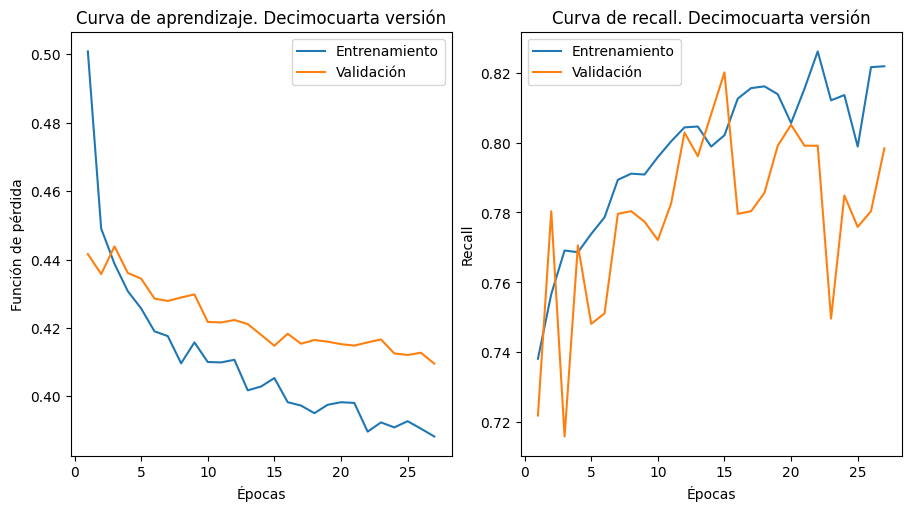

In [ ]:
# Curvas de pérdida y recall - Versión 14

import matplotlib.pyplot as plt

epochs = range(1, len(history_version14.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version14.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version14.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Decimocuarta versión"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version14.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version14.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Decimocuarta versión"
)

ax[1].legend()

plt.show()

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


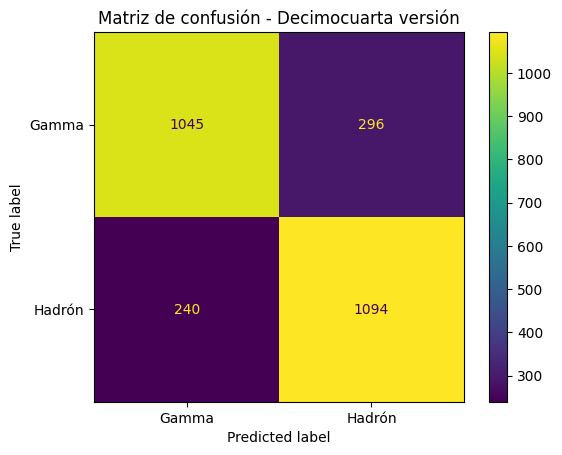

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo 14
Y_val_prob_v14 = version14.predict(X_val_scaled)

# Convertir probabilidades en clases
# Si >= 0.5, hadrón
# Si < 0.5, gamma
Y_val_pred_v14 = (Y_val_prob_v14 >= 0.5).astype(int)

# Matriz de confusión
conf_matrix_v14 = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_v14)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_v14,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Decimocuarta versión")
plt.show()

Nuevamente por encima de $0.8$. El mejor modelo de este tipo sigue siendo la versión 12 y se evidencia que este tipo de configuraciones dan, en promedio, un mejor recall. La accuracy se mantiene al nivel de los modelos pequeños.

**VERSIONES ADICIONALES:**
Ahora, según lo conversado con el profesor y con su ayuda, decidimos hacer un ciclo probando modelos más simples sin early stopping ni dropout a ver si obtenemos los mismos resultados.

In [ ]:


import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, recall_score



# Función para crear modelos


def crear_modelo_simple(capas_ocultas):

    modelo = Sequential()
    modelo.add(Input(shape=(6,)))

    for neuronas in capas_ocultas:
        modelo.add(Dense(neuronas, activation="relu"))

    modelo.add(Dense(1, activation="sigmoid")) # Sigmoide porque es clasificación binaria

    modelo.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy", tf.keras.metrics.Recall(name="recall")])

    return modelo



# Configuraciones a probar


configuraciones_simples = [

    {"arquitectura": (8,), "batch_size": 40, "epochs": 30},
    {"arquitectura": (16,), "batch_size": 40, "epochs": 30},
    {"arquitectura": (24,), "batch_size": 40, "epochs": 30},
    {"arquitectura": (16, 8), "batch_size": 32, "epochs": 40},
    {"arquitectura": (16, 8), "batch_size": 36, "epochs": 40},
    {"arquitectura": (16, 6), "batch_size": 32, "epochs": 40},
    {"arquitectura": (16, 10), "batch_size": 32, "epochs": 40},
    {"arquitectura": (24, 12), "batch_size": 32, "epochs": 50},
    {"arquitectura": (32, 16), "batch_size": 32, "epochs": 50},
    {"arquitectura": (64, 32), "batch_size": 32, "epochs": 50},
    {"arquitectura": (64, 32, 16), "batch_size": 32, "epochs": 50},
    {"arquitectura": (128, 64), "batch_size": 40, "epochs": 60},
    {"arquitectura": (128, 64, 32), "batch_size": 40, "epochs": 60},
    {"arquitectura": (256, 128), "batch_size": 40, "epochs": 60},
    {"arquitectura": (256, 128, 64), "batch_size": 40, "epochs": 60},
    {"arquitectura": (512, 256, 128), "batch_size": 40, "epochs": 70},
    {"arquitectura": (1024, 512, 256), "batch_size": 40, "epochs": 70},
    {"arquitectura": (1024, 512, 256, 128), "batch_size": 40, "epochs": 70},
]



# Entrenamiento de los modelos


resultados_simples = []
historias_simples = {}
matrices_simples = {}

tf.random.set_seed(20)

for i, config in enumerate(configuraciones_simples, start=1):

    nombre_modelo = f"Modelo simple {i}"

    print("Entrenando:", nombre_modelo)
    print("Arquitectura:", config["arquitectura"])
    print("Batch size:", config["batch_size"])
    print("Épocas:", config["epochs"])
    print("----------------------------------------")


    # Semilla para replicabilidad
    tf.random.set_seed(20)

    # Crear modelo
    modelo = crear_modelo_simple(capas_ocultas=config["arquitectura"])

    # Entrenamiento
    history = modelo.fit(
        X_train_scaled,
        Y_train,
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        validation_data=(X_val_scaled, Y_val),
        verbose=0
    )

    # Evaluación
    loss, accuracy_keras, recall_keras = modelo.evaluate(X_val_scaled,Y_val,verbose=0)

    # Predicciones
    Y_val_prob = modelo.predict(X_val_scaled, verbose=0)

    # Convertir probabilidades en clases
    # Si >= 0.5, hadrón
    # Si < 0.5, gamma
    Y_val_pred = (Y_val_prob >= 0.5).astype(int)

    # Matriz de confusión
    conf_matrix = confusion_matrix(
        np.ravel(Y_val),
        np.ravel(Y_val_pred)
    )

    TN, FP, FN, TP = conf_matrix.ravel()

    accuracy = accuracy_score(np.ravel(Y_val),np.ravel(Y_val_pred))

    recall = recall_score(np.ravel(Y_val),np.ravel(Y_val_pred))

    resultados_simples.append({
        "Modelo": nombre_modelo,
        "Arquitectura": config["arquitectura"],
        "Dropout": "No",
        "Early Stopping": "No",
        "Batch size": config["batch_size"],
        "Épocas": config["epochs"],
        "Función de pérdida validación": loss,
        "Accuracy validación": accuracy,
        "Recall validación": recall,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP
    })

    # Guardar historia y matriz para graficar después
    historias_simples[nombre_modelo] = history.history
    matrices_simples[nombre_modelo] = conf_matrix



# Tabla de resultados


tabla_modelos_simples = pd.DataFrame(resultados_simples)

tabla_modelos_simples_ordenada = tabla_modelos_simples.sort_values(by=["Recall validación", "FN", "Accuracy validación"],ascending=[False, True, False])

display(tabla_modelos_simples_ordenada)



# Cinco mejores modelos según recall

top_5_simples = tabla_modelos_simples_ordenada.head(5).copy()

display(top_5_simples)

Entrenando: Modelo simple 1
Arquitectura: (8,)
Batch size: 40
Épocas: 30
----------------------------------------
Entrenando: Modelo simple 2
Arquitectura: (16,)
Batch size: 40
Épocas: 30
----------------------------------------
Entrenando: Modelo simple 3
Arquitectura: (24,)
Batch size: 40
Épocas: 30
----------------------------------------
Entrenando: Modelo simple 4
Arquitectura: (16, 8)
Batch size: 32
Épocas: 40
----------------------------------------
Entrenando: Modelo simple 5
Arquitectura: (16, 8)
Batch size: 36
Épocas: 40
----------------------------------------
Entrenando: Modelo simple 6
Arquitectura: (16, 6)
Batch size: 32
Épocas: 40
----------------------------------------
Entrenando: Modelo simple 7
Arquitectura: (16, 10)
Batch size: 32
Épocas: 40
----------------------------------------
Entrenando: Modelo simple 8
Arquitectura: (24, 12)
Batch size: 32
Épocas: 50
----------------------------------------
Entrenando: Modelo simple 9
Arquitectura: (32, 16)
Batch size: 32
Épo

,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
9,Modelo simple 10,"(64, 32)",No,No,32,50,0.375119,0.820935,0.784858,1149,192,287,1047
4,Modelo simple 5,"(16, 8)",No,No,36,40,0.385997,0.820187,0.784858,1147,194,287,1047
8,Modelo simple 9,"(32, 16)",No,No,32,50,0.381085,0.814206,0.783358,1133,208,289,1045
10,Modelo simple 11,"(64, 32, 16)",No,No,32,50,0.377052,0.818318,0.782609,1145,196,290,1044
11,Modelo simple 12,"(128, 64)",No,No,40,60,0.379062,0.817570,0.782609,1143,198,290,1044
7,Modelo simple 8,"(24, 12)",No,No,32,50,0.383535,0.811589,0.777361,1134,207,297,1037
13,Modelo simple 14,"(256, 128)",No,No,40,60,0.376869,0.820561,0.773613,1163,178,302,1032
5,Modelo simple 6,"(16, 6)",No,No,32,40,0.391274,0.811215,0.773613,1138,203,302,1032
6,Modelo simple 7,"(16, 10)",No,No,32,40,0.386062,0.810841,0.770615,1141,200,306,1028
12,Modelo simple 13,"(128, 64, 32)",No,No,40,60,0.387441,0.816449,0.768366,1159,182,309,1025


,Modelo,Arquitectura,Dropout,Early Stopping,Batch size,Épocas,Función de pérdida validación,Accuracy validación,Recall validación,TN,FP,FN,TP
9,Modelo simple 10,"(64, 32)",No,No,32,50,0.375119,0.820935,0.784858,1149,192,287,1047
4,Modelo simple 5,"(16, 8)",No,No,36,40,0.385997,0.820187,0.784858,1147,194,287,1047
8,Modelo simple 9,"(32, 16)",No,No,32,50,0.381085,0.814206,0.783358,1133,208,289,1045
10,Modelo simple 11,"(64, 32, 16)",No,No,32,50,0.377052,0.818318,0.782609,1145,196,290,1044
11,Modelo simple 12,"(128, 64)",No,No,40,60,0.379062,0.817570,0.782609,1143,198,290,1044


Vemos un recall bajo en todos que no se asemeja al del modelo grande. No obstante, queda una última recomendación del profesor: ajustaremos el umbral de decisión del top 5 y, basados en esos resultados, decidiremos entre alguno de los 5 anteriores o el modelo grande (versión 12).

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score


def crear_modelo_simple(capas_ocultas):

    modelo = Sequential()
    modelo.add(Input(shape=(6,)))

    for neuronas in capas_ocultas:
        modelo.add(Dense(neuronas, activation="relu"))

    modelo.add(Dense(1, activation="sigmoid")) # Sigmoide porque es clasificación binaria

    modelo.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy", tf.keras.metrics.Recall(name="recall")])

    return modelo


configuraciones_umbral = [
    {
        "Modelo": "Modelo simple 10",
        "Arquitectura": (64, 32),
        "Batch size": 32,
        "Épocas": 50
    },
    {
        "Modelo": "Modelo simple 5",
        "Arquitectura": (16, 8),
        "Batch size": 36,
        "Épocas": 40
    },
    {
        "Modelo": "Modelo simple 9",
        "Arquitectura": (32, 16),
        "Batch size": 32,
        "Épocas": 50
    },
    {
        "Modelo": "Modelo simple 11",
        "Arquitectura": (64, 32, 16),
        "Batch size": 32,
        "Épocas": 50
    },
    {
        "Modelo": "Modelo simple 12",
        "Arquitectura": (128, 64),
        "Batch size": 40,
        "Épocas": 60
    }
]


# Umbrales

umbrales = [0.30, 0.35, 0.40]


# Entrenamiento y evaluación por umbral


resultados_umbrales_simples = []

for config in configuraciones_umbral:

    print("Entrenando:", config["Modelo"])
    print("Arquitectura:", config["Arquitectura"])
    print("Batch size:", config["Batch size"])
    print("Épocas:", config["Épocas"])
    print("----------------------------------------")


    # Semilla para replicabilidad
    tf.random.set_seed(20)

    # Crear modelo
    modelo = crear_modelo_simple(
        capas_ocultas=config["Arquitectura"]
    )

    # Entrenamiento
    history = modelo.fit(
        X_train_scaled,
        Y_train,
        epochs=config["Épocas"],
        batch_size=config["Batch size"],
        validation_data=(X_val_scaled, Y_val),
        verbose=0
    )

    # Probabilidades predichas
    Y_val_prob = modelo.predict(X_val_scaled, verbose=0)

    for umbral in umbrales:

        # Convertir probabilidades en clases
        # Si >= umbral, hadrón
        # Si < umbral, gamma
        Y_val_pred = (Y_val_prob >= umbral).astype(int)

        # Matriz de confusión
        conf_matrix = confusion_matrix(
            np.ravel(Y_val),
            np.ravel(Y_val_pred)
        )

        TN, FP, FN, TP = conf_matrix.ravel()

        # Métricas
        accuracy = accuracy_score(
            np.ravel(Y_val),
            np.ravel(Y_val_pred)
        )

        recall = recall_score(
            np.ravel(Y_val),
            np.ravel(Y_val_pred)
        )


        resultados_umbrales_simples.append({
            "Modelo": config["Modelo"],
            "Arquitectura": config["Arquitectura"],
            "Umbral": umbral,
            "Accuracy": accuracy,
            "Recall": recall,
            "TN": TN,
            "FP": FP,
            "FN": FN,
            "TP": TP
        })


#Results
tabla_umbrales_simples = pd.DataFrame(resultados_umbrales_simples)

tabla_umbrales_simples_ordenada = tabla_umbrales_simples.sort_values(
    by=["Recall", "FN", "Accuracy"],
    ascending=[False, True, False]
)

display(tabla_umbrales_simples_ordenada)

Entrenando: Modelo simple 10
Arquitectura: (64, 32)
Batch size: 32
Épocas: 50
----------------------------------------
Entrenando: Modelo simple 5
Arquitectura: (16, 8)
Batch size: 36
Épocas: 40
----------------------------------------
Entrenando: Modelo simple 9
Arquitectura: (32, 16)
Batch size: 32
Épocas: 50
----------------------------------------
Entrenando: Modelo simple 11
Arquitectura: (64, 32, 16)
Batch size: 32
Épocas: 50
----------------------------------------
Entrenando: Modelo simple 12
Arquitectura: (128, 64)
Batch size: 40
Épocas: 60
----------------------------------------


,Modelo,Arquitectura,Umbral,Accuracy,Recall,TN,FP,FN,TP
6,Modelo simple 9,"(32, 16)",0.30,0.788785,0.918291,885,456,109,1225
3,Modelo simple 5,"(16, 8)",0.30,0.782804,0.915292,873,468,113,1221
9,Modelo simple 11,"(64, 32, 16)",0.30,0.798131,0.912294,918,423,117,1217
0,Modelo simple 10,"(64, 32)",0.30,0.797757,0.910795,919,422,119,1215
12,Modelo simple 12,"(128, 64)",0.30,0.800748,0.907796,931,410,123,1211
4,Modelo simple 5,"(16, 8)",0.35,0.792150,0.895052,925,416,140,1194
10,Modelo simple 11,"(64, 32, 16)",0.35,0.806729,0.888306,973,368,149,1185
7,Modelo simple 9,"(32, 16)",0.35,0.801869,0.888306,960,381,149,1185
13,Modelo simple 12,"(128, 64)",0.35,0.809720,0.883058,988,353,156,1178
1,Modelo simple 10,"(64, 32)",0.35,0.807103,0.882309,982,359,157,1177


Encontramos excelentes resultados. Haciendo un riguroso examen de la tabla, vemos que las mejores combinaciones accuracy-recall se encuentran para el umbral de $0.35.$ En particular, la arquitectura $(128, 64)$ muestra un buen balance: el mejor accuracy por mucho junto a un recall que es elevado.

A lo largo del proceso de experimentación se evaluaron 14 versiones de arquitecturas
de red neuronal, variando sistemáticamente el número de capas ocultas, el número de
neuronas, el uso de Dropout y Early Stopping, el número de épocas y el umbral de
clasificación. La tabla comparativa anterior resume las métricas obtenidas en el conjunto
de validación para cada versión.

### Análisis comparativo

Las principales conclusiones del proceso de búsqueda de arquitectura son:

- Versiones 1 y 2 (arquitecturas simples, sin regularización): establecieron una
  línea base con recall entre $0.76$ y $0.79$. Las curvas de aprendizaje no mostraron
  overfitting, pero el recall fue insuficiente.

- Versiones 3 y 4 (introducción de Dropout y capas adicionales): el recall empeoró
  inicialmente, sugiriendo que la regularización excesiva limitaba la capacidad del modelo
  en esta etapa.

- Versiones 5 a 8 (ajuste fino de hiperparámetros): el recall mejoró progresivamente
  hasta valores cercanos a $0.82$. El accuracy se mantuvo estable, lo que indica que las
  mejoras en recall no se obtuvieron a costa de un deterioro general del modelo.

- Versión 9: obtuvo el mejor recall de validación entre los modelos simples
  ($\approx 0.837$), con curvas de aprendizaje estables y sin señales de sobreajuste ni
  subajuste. Esto la posicionó como candidata principal.

- Versiones 12 a 14 (modelos grandes): confirmaron que arquitecturas más profundas
  pueden alcanzar recall superiores a $0.8$, aunque sin mejorar sustancialmente sobre la
  versión 9.

- Exploración de umbrales: al evaluar distintos umbrales de clasificación sobre los
  mejores modelos, se encontró que el umbral $\hat{y} \geq 0.35$ maximiza el recall
  manteniendo un accuracy competitivo. En particular, la arquitectura $(128, 64)$ con
  este umbral mostró el mejor balance entre ambas métricas.

### Selección del modelo final

Con base en el análisis anterior, se seleccionó la arquitectura $(128, 64)$ con umbral
$\hat{y} \geq 0.35$ como modelo final. Esta decisión se fundamenta en tres criterios:

1. Recall más alto entre todas las configuraciones evaluadas en validación.
2. Curvas de aprendizaje estables, sin evidencia de sobreajuste ni subajuste.
3. Umbral ajustado a la asimetría clínica del problema, priorizando la identificación
   correcta de hadrones sobre la precisión global.

**VERSIÓN FINAL**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
import tensorflow as tf

# Semilla para replicabilidad
tf.random.set_seed(20)

# Modelo final
version_final = Sequential([
    Input(shape=(6,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid") # Sigmoide porque es clasificación binaria
])

version_final.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Recall(name="recall")]
)

version_final.summary()


# Entrenamiento del modelo final
history_version_final = version_final.fit(
    X_train_scaled,
    Y_train,
    epochs=60,
    batch_size=40,
    validation_data=(X_val_scaled, Y_val),
    verbose=0
)

# Evaluación de la función de pérdida en validación
loss_final = version_final.evaluate(
    X_val_scaled,
    Y_val,
    verbose=0
)[0]

print("---------------- MÉTRICAS MODELO FINAL ------------------------")
print("Loss validación:", loss_final)

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_35 (Dense)                │ (None, 128)            │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,217 (36.00 KB)

 Trainable params: 9,217 (36.00 KB)

 Non-trainable params: 0 (0.00 B)

---------------- MÉTRICAS MODELO FINAL ------------------------
Loss validación: 0.3763958513736725


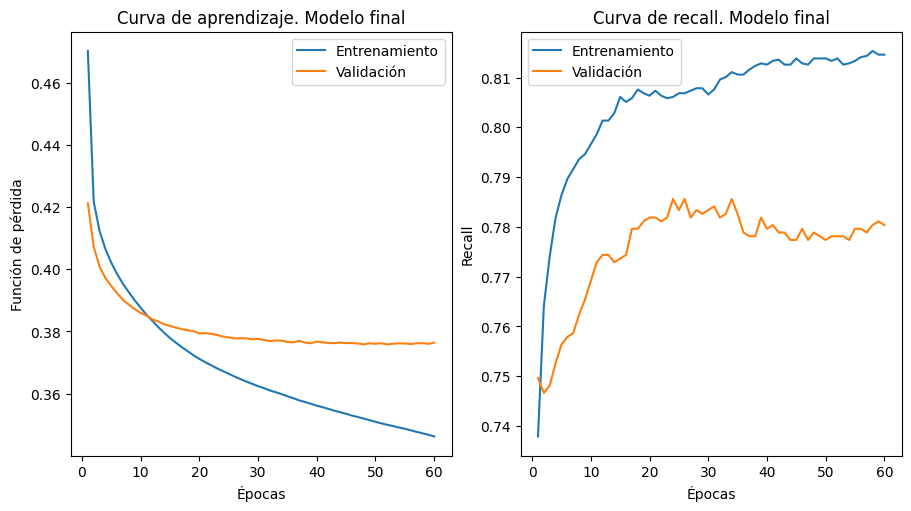

In [ ]:
# Curvas de pérdida y recall - Modelo final

import matplotlib.pyplot as plt

epochs = range(1, len(history_version_final.history["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 5), layout="constrained")

# Función de pérdida
ax[0].plot(epochs, history_version_final.history["loss"], label="Entrenamiento")
ax[0].plot(epochs, history_version_final.history["val_loss"], label="Validación")

ax[0].set(
    xlabel="Épocas",
    ylabel="Función de pérdida",
    title="Curva de aprendizaje. Modelo final"
)

ax[0].legend()

# Recall
ax[1].plot(epochs, history_version_final.history["recall"], label="Entrenamiento")
ax[1].plot(epochs, history_version_final.history["val_recall"], label="Validación")

ax[1].set(
    xlabel="Épocas",
    ylabel="Recall",
    title="Curva de recall. Modelo final"
)

ax[1].legend()

plt.show()

**Importante**: las curvas se calculan con un umbral de 0.5. Por lo que no son tan relevantes en este caso.

84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


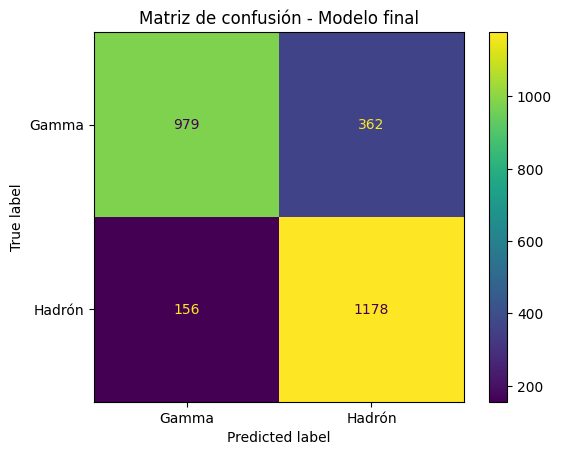

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

# Probabilidades predichas por el modelo final
Y_val_prob_final = version_final.predict(X_val_scaled)

# Convertir probabilidades en clases usando umbral 0.35
# Si >= 0.35, hadrón
# Si < 0.35, gamma
umbral_final = 0.35
Y_val_pred_final = (Y_val_prob_final >= umbral_final).astype(int)

# Matriz de confusión
conf_matrix_final = confusion_matrix(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_final)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix_final,
    display_labels=["Gamma", "Hadrón"]
)

disp.plot()
plt.title("Matriz de confusión - Modelo final")
plt.show()

In [ ]:
# Extraer valores de la matriz de confusión

TN_final, FP_final, FN_final, TP_final = conf_matrix_final.ravel()

accuracy_final = accuracy_score(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_final)
)

recall_final = recall_score(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_final)
)

precision_final = precision_score(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_final)
)

f1_final = f1_score(
    np.ravel(Y_val),
    np.ravel(Y_val_pred_final)
)

print("---------------- MÉTRICAS MODELO FINAL ------------------------")
print("Loss validación:", loss_final)
print("Accuracy validación:", accuracy_final)
print("Recall validación:", recall_final)

---------------- MÉTRICAS MODELO FINAL ------------------------
Loss validación: 0.3763958513736725
Accuracy validación: 0.8063551401869159
Recall validación: 0.8830584707646177


Esto supera al modelo grande. Esta será nuestra elección.

In [ ]:
# Guardar modelo final

import joblib

version_final.save("/content/drive/MyDrive/modelo_definitivo_hadron.keras")

joblib.dump(scaler,"/content/drive/MyDrive/scaler_modelo_definitivo.pkl")

['/content/drive/MyDrive/scaler_modelo_definitivo.pkl']

##5. Modelo Final

Tras evaluar múltiples arquitecturas y umbrales de decisión, el modelo seleccionado
corresponde a la arquitectura $(128, 64)$ con umbral de clasificación $\hat{y} \geq 0.35$,
por presentar el mejor balance entre recall y accuracy en el conjunto de validación.

### Arquitectura

| Capa | Tipo | Neuronas | Activación |
|------|------|----------|------------|
| Entrada | Dense | $6$ | — |
| Oculta 1 | Dense | $128$ | ReLU |
| Oculta 2 | Dense | $64$ | ReLU |
| Salida | Dense | $1$ | Sigmoide |

### Hiperparámetros

| Hiperparámetro | Valor |
|----------------|-------|
| Optimizador | Adam |
| Tasa de aprendizaje | $\eta = 0.001$ |
| Función de pérdida | Binary Cross-Entropy |
| Épocas | $60$ |
| Batch size | $40$ |
| Umbral de clasificación | $\hat{y} \geq 0.35$ |

In [ ]:
#Generación de predictions.csv - Modelo Final (9)
import pandas as pd
import numpy as np
from google.colab import drive
import tensorflow as tf
import joblib
import os
import sys
import shutil # Import shutil for file operations

drive.mount("/content/drive", force_remount=True)

# Añadir el directorio que contiene el archivo helpers.py
sys.path.append("/content/sample_data/")

# directorios del modelo y scaler
model_drive_zipped_path = "/content/drive/MyDrive/modelo_definitivo_hadron.keras.zip"
model_local_keras_path = "/content/modelo_definitivo_hadron.keras"
scaler_path = "/content/drive/MyDrive/scaler_modelo_definitivo.pkl"


# cargar el modelo final desde el archivo .keras
modelo_final = tf.keras.models.load_model(model_local_keras_path)
print(f"Model loaded successfully from {model_local_keras_path}")

# cargar el scaler
scaler = joblib.load(scaler_path)

# Cargar test set
test_data_path = "/content/sample_data/hadron_test.csv"
if not os.path.exists(test_data_path):
    print(f"ERROR: El archivo '{test_data_path}' no se encontró.")
    print("Por favor, asegúrese de que 'hadron_test.csv' esté presente en el directorio '/content/sample_data/'.")
    print("Puede subir el archivo a Colab o montarlo desde Google Drive y ajustar la ruta si es necesario.")
    raise FileNotFoundError(f"Missing required file: {test_data_path}")
else:
    df_test = pd.read_csv(test_data_path)

df_test = df_test.drop(columns="Unnamed: 0")

# Escalar y predecir con umbral 0.35
X_test_scaled = scaler.transform(df_test)
Y_test_prob = modelo_final.predict(X_test_scaled)
Y_test_pred = (Y_test_prob >= 0.35).astype(int)

# Exportar
df_predictions = df_test.copy()
df_predictions["prediction"] = np.ravel(Y_test_pred)
df_predictions.to_csv("predictions.csv", index=False)
print(df_predictions["prediction"].value_counts())

from helpers import check_requirements
check_requirements()
from google.colab import files
files.download("predictions.csv")

Mounted at /content/drive
Model loaded successfully from /content/modelo_definitivo_hadron.keras
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
prediction
1    1575
0    1101
Name: count, dtype: int64
Archivos encontrados: ['predictions.csv']
Archivo cargado correctamente
El archivo predictions.csv no está vacío
Todas las columnas requeridas están presentes, con los nombres adecuados.
El archivo contiene las 2676 filas requeridas.
Requisitos completados


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Análisis del modelo final desde el contexto del problema

### 6.1 Interpretación clínica de las métricas

El problema de clasificación de haces en hadronterapia no es un problema simétrico: los errores no tienen el mismo costo clínico. Para entender esto, es necesario traducir la matriz de confusión al contexto médico:

- Verdadero Positivo (TP): el modelo indentifica correctamente un hadrón, el haz es transportado al gantry y usado en el tratamiento. :)

- Verdadero Negativo (TN): el modelo identifica correctamente un rayo gamma, el hadrón es descartado correctamente. :)

- Falso Negativo: el modelo clasifica un hadrón como rayo gamma, un haz terapéutico válido es descartado, por ende el paciente recibe menos dosis de la planificada. :(

- Falso Positivo(FP): el modelo clasifica un rayo gamma como hadrón, un rayo gamma llega al gantry y potencialmente al paciente, comprometiendo la precisón del tratamiento. :(

Dado que el objetivo de la hadronterapia es depositar la dosis máxima exactamente sobre el tumor aprovechando el pico de Bragg, ambos tipos de errores son indeseables. Sin embargo, un falso negativo implica una reducción directa de la eficacia terapéutica , mientras que un falso positivo introduce una radiación no controlada que puede dañar tejido sano adyacente.

Por esta misma razón, el recall:

$$\text{Recall} = \frac{TP}{TP + FN}$$

es la métrica prioritaria del reto: mide qué fracción de los hadrones reales el modelo logra identificar correctamente, minimizando asi los falsos negativos.

---

### 6.2 Justificación del umbral de clasificación

El umbral estándar de $0.5$ fue reemplazado por $\hat{y} \geq 0.35$. Esto significa que el modelo clasifica un haz como hadrón con menos certeza probabilística, siendo más conservador en el descarte. Esta decisión refleja directamente la asimetría clínica descrita: es preferible admitir un rayo gamma que descartar un hadrón válido. El ajuste del umbral permitió incrementar el recall de validación de forma significativa con una reducción moderada del accuracy, lo cual es el intercambio correcto para esta aplicación

---

### 6.3 Viabilidad del sistema en un entorno clínico real

El modelo final, es una red neuronal con una arquitectura $(128, 64)$, optimizador ADAM y umbral $0.35$. Logra una clasificación automática en tiempo real a partir de seis variables físicas medidas por el detector. Esto tiene implicaciones prácticas relevantes:

- Velocidad: una red neuronal feedforward de este tamaño realiza inferencia en milisegundos, compatible con los tiempos de operación de un acelerador de particulas.
-Automatización: elimina la necesidad de intervención humana en la selección del haz, reduciendo errores operativos.
-Escalabilidad: el modelo puede reentrenarse con nuevos datos del detector sin cambiar la arquitectura del sistema.

No obstante, para su uso clínico real sería necesario validar el modelo con datos de múltiples detectores y condiciones de operación distintas, dado que fue entrenado sobre un único conjunto de datos. Adicionalmente, un recall alto pero no perfecto implica que algunos hadrones seguirán siendo descartados, por lo cual el sistema debería operar como una primera etapa de filtrado, complementada con verificación física adicional en contextos de alta importancia.
